**Load Data**

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
from scipy.stats import gmean
from sklearn.impute import KNNImputer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
import itertools
from sklearn.model_selection import cross_validate, KFold
import plotly.graph_objects as go

In [3]:
RANDOM_STATE = 42
N_SPLITS = 2

**Load data**

In [4]:
df = pd.read_csv('quang_ninh_wqi_v8.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1110 entries, 0 to 1109
Data columns (total 43 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Location  1110 non-null   object
 1   ID        1106 non-null   object
 2   Month     1110 non-null   object
 3   Temp      1110 non-null   object
 4   pH        1110 non-null   object
 5   DO        1110 non-null   object
 6   Sal       954 non-null    object
 7   Turb      954 non-null    object
 8   TSS       1110 non-null   object
 9   COD       1110 non-null   object
 10  BOD5      1110 non-null   object
 11  SO4       156 non-null    object
 12  NO3       1110 non-null   object
 13  NO2       1110 non-null   object
 14  NH4       1110 non-null   object
 15  PO4       1110 non-null   object
 16  MBAS      954 non-null    object
 17  Cyan      954 non-null    object
 18  Fluor     954 non-null    object
 19  Cl        1110 non-null   object
 20  OilFat    1110 non-null   object
 21  Coliform  1110

Location: Sampling location

ID: Unique sample identifier

Month: Monitoring month

Temp: Water temperature in Celsius

pH: pH level

DO: Dissolved Oxygen in mg/L

Sal: Salinity of water

Turb: Water turbidity

TSS: Total Suspended Solids in mg/L

COD: Chemical Oxygen Demand in mg/L

BOD5: Biochemical Oxygen Demand over 5 days in mg/L

SO4: Sulfate concentration in mg/L

NO3: Nitrate concentration in mg/L

NO2: Nitrite concentration in mg/L

NH4: Ammonium concentration in mg/L

PO4: Phosphate concentration in mg/L

MBAS: Surfactant content (MBAS method)

Cyan: Cyanide concentration

Fluor: Fluoride concentration

Cl: Chloride concentration in mg/L

OilFat: Total oil and fat content in mg/L

Coliform: Coliform bacteria count (MPN/100ml)

EColi: E. Coli bacteria count

As: Arsenic concentration in mg/L

Hg: Mercury concentration in mg/L

Pb: Lead concentration in mg/L

Cd: Cadmium concentration in mg/L

Fe: Iron concentration in mg/L

Mn: Manganese concentration

Cu: Copper concentration

Ni: Nickel concentration

Zn: Zinc concentration

Cr: Chromium concentration

CrVI: Hexavalent Chromium concentration

Phenol: Total phenol content

RadAlpha: Total alpha radioactivity

RadBeta: Total beta radioactivity

Aldrin: Aldrin pesticide concentration

BHC: BHC pesticide concentration

Dieldrin: Dieldrin pesticide concentration

DDTs: DDT and its derivatives concentration

Heptach: Heptachlor & Heptachloreproxide concentration

TOC: Total Organic Carbon

# 1. Data Pre-processing


---

**Drop irrelevant columns**

In [6]:
df_dropped = df.drop([
    'Location', 'ID', 'Month', 'Sal', 'Turb', 'TSS', 'SO4', 'MBAS', 'Cyan', 'Fluor',
    'Cl', 'OilFat', 'Fe', 'Mn', 'Cu', 'Ni', 'Zn', 'Cr', 'Phenol',
    'RadAlpha', 'RadBeta'
], axis=1)

Drop some columns which don't impact to WQI scores

## 1.1 Data type conversion

In [7]:
non_numeric_values_dropped = {}
for col in df_dropped.columns:
    # Create a boolean series for values that are neither numeric nor NaN
    is_not_numeric_and_not_nan = df_dropped[col].apply(lambda x: not (isinstance(x, (int, float)) or pd.isna(x)))

    if is_not_numeric_and_not_nan.any():
        # Use this boolean series to filter the original column
        non_numeric_entries = df_dropped[col][is_not_numeric_and_not_nan]
        non_numeric_values_dropped[col] = non_numeric_entries.unique().tolist()

if non_numeric_values_dropped:
    print("Non-numeric values found in df_dropped (excluding NaN):")
    for col, values in non_numeric_values_dropped.items():
        print(f"- {col}: {values}")
else:
    print("No non-numeric values found in df_dropped (excluding NaN).")

Non-numeric values found in df_dropped (excluding NaN):
- Temp: ['21,5', '24,1', '28,4', '26,7', '17,1', '24,8', '27,3', '26,6', '19,6', '24,5', '30,2', '28,8', '19', '25,5', '30,8', '29,5', '20', '25,3', '21.3', '24,7', '29,8', '29,3', '19.6', '26,2', '31,3', '18.9', '26,4', '31,6', '27,8', 'KCM', '28,1', '32,1', '27,6', '18', '30,6', '21,6', '17.1', '22,1', '16.7', '25,6', '27,4', '20,2', '23,7', '20,8', '19.3', '26,3', '21,3', '19.9', '30,4', '19.7', '19.5', '17.8', '24,4', '23,1', '18.4', '24,2', '32,2', '22,6', '18.1', '26,1', '23,4', '20.1', '25,7', '30,5', '25,8', '27,1', '17', '25,9', '34,1', '23,3', '18,3', '30,9', '19,3', '29,1', '19,8', '26,8', '34,2', '29,6', '18,2', '24,3', '31,1', '29,4', '21,2', '33', '37,2', '28,3', '33,5', '35,8', '27,9', '18,9', '32,6', '20,3', '29,7', '20,6', '33,4', '28,2', '32,4', '28,9', '20,1', '26', '29,9', '27,7', '17,3', '31,8', '22,5', '22,2', '16,5', '21,8', '32,3', '25,4', '16,4', '16,7', '18,7', '31,4', '25,1', '23,2', '18,6', '23,5', '27,

Non-numeric values found (excluding NaN):

| Value     | Meaning / Issue                                           |
|-----------|-----------------------------------------------------------|
| `x`       | Missing value (NaN)                                       |
| `X`       | Missing value (NaN)                                       |
| `<x`      | Missing / below detection                                  |
| `x,x  `   | Invalid numeric format (string instead of number)         |
| `KCM`     | Special missing value / placeholder                       |


In [8]:
def handle_less_than_numeric(val):
    # If the value is a string
    if isinstance(val, str):
        val = val.strip()
        # If it matches the pattern "<x" or "<x.y"
        match = re.fullmatch(r'<\s*([0-9,]*\.?[0-9]+)', val)
        if match:
            x_str = match.group(1).replace(',', '.')
            return float(x_str)
        # If it's a numeric string with comma or dot
        try:
            return float(val.replace(',', '.'))
        except ValueError:
            return val
    # If it's already a number, keep as is
    elif isinstance(val, (int, float)):
        return val
    # Other values remain unchanged
    return val

# Apply the conversion to handle "<" and numeric strings
df_parsed = df_dropped.applymap(handle_less_than_numeric)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_16740\435176935.py:22: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_parsed = df_dropped.applymap(handle_less_than_numeric)


Cells with values less than x will be converted to type x, and cells with values using a comma instead of a dot will be converted to use a dot.

In [9]:
df_cleaned = df_parsed.replace('KCM', np.nan)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_16740\308843203.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cleaned = df_parsed.replace('KCM', np.nan)


KCM: Value could not be measured. These cells will be converted into NaN

In [10]:
df_replaced_X = df_cleaned.replace('X', np.nan)
df_replaced_x = df_replaced_X.replace('x', np.nan)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_16740\1174373341.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_replaced_x = df_replaced_X.replace('x', np.nan)


Some cells contain 'x' instead of being empty, so the missing values were standardized and the number of missing values was calculated.


In [11]:
def convert_column_type(col):
    # Remove NaN to check
    non_na = col.dropna()

    # Check if all are numbers
    if non_na.apply(lambda x: isinstance(x, (int, float))).all():
        return col.astype(float)
    else:
        return col.astype('category')

# Convert all to numeric (if not a number → NaN)
df_typed = df_replaced_x.apply(convert_column_type)

Convert column data types to appropriate types

In [12]:
df_typed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1110 entries, 0 to 1109
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Temp      1101 non-null   float64
 1   pH        1101 non-null   float64
 2   DO        1101 non-null   float64
 3   COD       1101 non-null   float64
 4   BOD5      1101 non-null   float64
 5   NO3       1101 non-null   float64
 6   NO2       1101 non-null   float64
 7   NH4       1101 non-null   float64
 8   PO4       1101 non-null   float64
 9   Coliform  1101 non-null   float64
 10  EColi     946 non-null    float64
 11  As        1101 non-null   float64
 12  Hg        1101 non-null   float64
 13  Pb        1101 non-null   float64
 14  Cd        1101 non-null   float64
 15  CrVI      946 non-null    float64
 16  Aldrin    335 non-null    float64
 17  BHC       335 non-null    float64
 18  Dieldrin  335 non-null    float64
 19  DDTs      335 non-null    float64
 20  Heptach   335 non-null    floa

The dataset has already been converted to the appropriate data types

## 1.2 Missing Values and Data Splitting


---

In [13]:
df_missing75_removed = df_typed.drop([
    'Aldrin', 'BHC', 'Dieldrin', 'DDTs', 'Heptach', 'TOC'
], axis=1)

Columns with about 75% missing values were removed.

In [14]:
final_data = df_missing75_removed.dropna(how='all')

print(f"Original DataFrame shape: {df_missing75_removed.shape}")
print(f"DataFrame shape after dropping rows with all NaN: {final_data.shape}")
print(f"{df_missing75_removed.shape[0]- final_data.shape[0]} records containing all NaN values were removed.")

Original DataFrame shape: (1110, 16)
DataFrame shape after dropping rows with all NaN: (1101, 16)
9 records containing all NaN values were removed.


I chose to remove records containing NaN values because there are only 9 such records, which is negligible compared to the overall dataset, and removing them will not significantly affect the analysis.

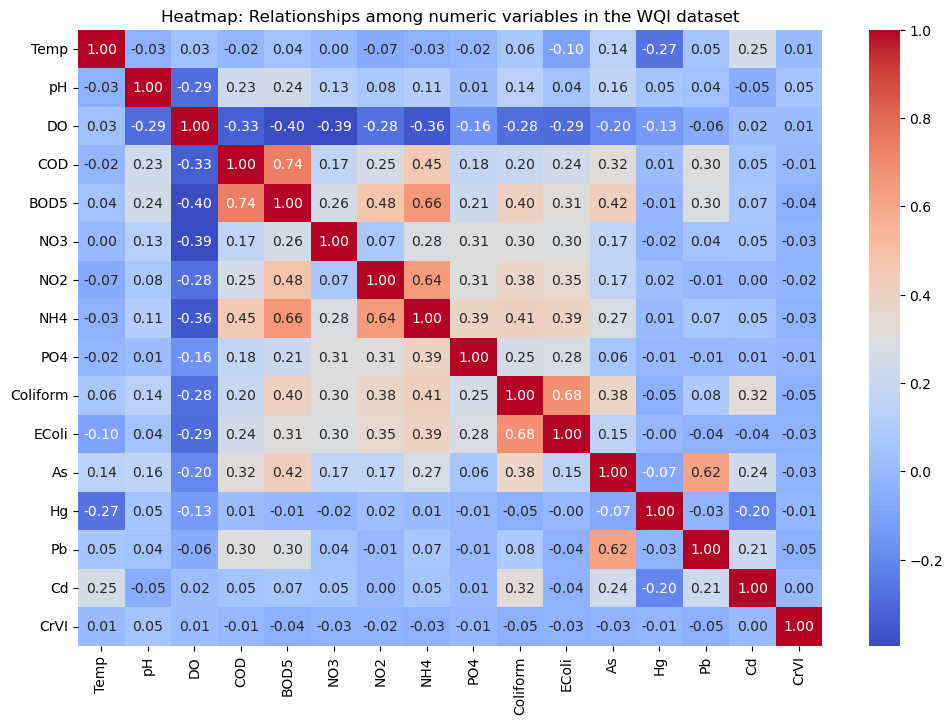

In [15]:
# Select numeric columns
numeric_cols = final_data.select_dtypes(include=['int64', 'float64']).columns
df_numeric = final_data[numeric_cols]

# Compute the correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationships among numeric variables in the WQI dataset")
plt.show()

In [16]:
def knn_fill_columns(df):
    num_cols_to_impute = ['EColi', 'CrVI']

    other_num_cols = [col for col in df.select_dtypes(include='number').columns
                  if col not in num_cols_to_impute]

    df_KNNfilled = df.copy()

    imputer = KNNImputer(n_neighbors=5)

    df_KNNfilled[num_cols_to_impute] = imputer.fit_transform(
        df_KNNfilled[num_cols_to_impute + other_num_cols]
    )[:, :len(num_cols_to_impute)]
    
    return df_KNNfilled

df_KNNfilled = knn_fill_columns(final_data)


I choose KNN because it better preserves the multivariate relationships between water quality parameters, making the imputed values more realistic. It also maintains the variance and distribution of the data, avoiding the loss of extreme values that are important for WQI. KNN improves machine learning model performance by providing context-aware imputations and is well-suited to the environmental similarity inherent in monitoring data. Overall, it leads to more accurate and reliable WQI predictions.

## 1.3 Calculate the WQI output

---

The WQI was calculated using the formula provided by the Vietnamese government.

In [17]:
# 1. Configure the BP threshold values for each metal
# The order of values corresponds to i = 1, 2, 3, 4, 5
metal_configs = {
    'As':   [0.01, 0.02, 0.05, 0.1,  0.1],
    'Cd':   [0.005, 0.005, 0.008, 0.01, 0.1],
    'Pb':   [0.02, 0.02, 0.04, 0.05, 0.5],
    'CrVI': [0.01, 0.02, 0.04, 0.05, 0.1],
    'Cu':   [0.1, 0.2, 0.5, 1.0, 2.0],
    'Zn':   [0.5, 1.0, 1.5, 2.0, 3.0],
    'Hg':   [0.001, 0.001, 0.0015, 0.002, 0.01]
}

# q values corresponding to levels i from 1 to 5
q_values = [100, 75, 50, 25, 10]

# 2. General WQI calculation function
def calculate_wqi_generic(cp, bp_list):
    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # If Cp is better than or equal to the highest standard level (level 1)
    if cp <= bp_list[0]:
        return q_values[0]

    # If Cp is worse than or equal to the lowest standard level (level 5)
    if cp >= bp_list[4]:
        return q_values[4]

    # Find the interval to apply Formula 1
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i <= cp <= bp_i1:
            # Case when bp_i == bp_i1 (like Pb, Hg at levels 1-2)
            if cp == bp_i and i != 0:
                return q_values[i]
            if cp == bp_i1 and i != 4:
                return q_values[i+1]

            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

In [18]:
def calculate_wqi_do(do_measured, temp):
    """
    Calculate the WQI for the DO parameter based on temperature and dissolved oxygen concentration.
    do_measured: Column 'DO mg/L'
    temp: Column 'Temperature (°C)'
    """
    if pd.isna(do_measured) or pd.isna(temp) or not isinstance(do_measured, (int, float)) or not isinstance(temp, (int, float)):
        return np.nan

    # Step 1: Calculate saturated DO (DO_saturated) based on temperature T
    # Formula: 14.652 - 0.41022*T + 0.0079910*T^2 - 0.0000777747*T^3
    do_sat = (14.652 - 0.41022 * temp +
              0.0079910 * (temp**2) -
              0.000077774 * (temp**3))

    # Calculate DO % saturation (Cp)
    cp = (do_measured / do_sat) * 100

    # Table 3: Standard values of BPi and qi for DO % saturation
    bp_do = [20, 50, 75, 88, 112, 125, 150, 200]
    q_do = [25, 50, 75, 100, 100, 75, 50, 25]

    # Check if Cp exactly matches any breakpoint values in the table
    for i, bp_val in enumerate(bp_do):
        if round(cp, 2) == bp_val:
            return q_do[i]

    if cp < 20 or cp > 200:
        return 10

    if 88 <= cp <= 112:
        return 100

    # Case 20 < Cp < 88: Use Formula 2
    if 20 < cp < 88:
        # Determine the interval i
        for i in range(0, 3): # Only consider breakpoints 20, 50, 75, 88
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 2: WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
                wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
                return round(wqi, 2)

    # Case 112 < Cp < 200: Use Formula 1
    if 112 < cp < 200:
        # Determine the interval i (breakpoints 112, 125, 150, 200)
        for i in range(4, 7):
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 1: WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
                wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
                return round(wqi, 2)

In [19]:
def calculate_wqi_ph(cp):
    """
    Calculate the WQI for the pH parameter based on Table 4 and interpolation formulas.
    cp: observed pH value.
    """

    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # Table 4: Regulations for BPi and qi values for pH
    # i=1: <5.5 (q=10), i=2: 5.5 (q=50), i=3: 6 (q=100)
    # i=4: 8.5 (q=100), i=5: 9 (q=50), i=6: >9 (q=10)

    # 1. Case when the value is outside the range or exactly at an extreme boundary
    if cp < 5.5 or cp > 9:
        return 10


    # 2. Case when the value exactly matches the breakpoint values in the table
    if cp == 5.5: return 50
    if cp == 6.0: return 100
    if cp == 8.5: return 100
    if cp == 9.0: return 50

    # 3. Case when 5.5 < pH < 6: Use Formula 2
    if 5.5 < cp < 6:
        # i=2 (BPi=5.5, qi=50); i+1=3 (BPi+1=6, qi+1=100)
        bp_i, bp_i1 = 5.5, 6.0
        q_i, q_i1 = 50, 100
        # WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
        wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
        return round(wqi, 2)

    # 4. Case when 6 <= pH <= 8.5: WQI = 100
    if 6 <= cp <= 8.5:
        return 100

    # 5. Case when 8.5 < pH < 9: Use Formula 1
    if 8.5 < cp < 9:
        # i=4 (BPi=8.5, qi=100); i+1=5 (BPi+1=9, qi+1=50)
        bp_i, bp_i1 = 8.5, 9.0
        q_i, q_i1 = 100, 50
        # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
        wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
        return round(wqi, 2)


In [20]:
# 1. Set up the BP benchmark values table for each parameter
# Corresponding q values order: 100, 75, 50, 25, 10
q_values = [100, 75, 50, 25, 10]

params_config = {
    'BOD5':          [4, 6, 15, 25, 50],
    'COD':           [10, 15, 30, 50, 150],
    'TOC':                [4, 6, 15, 25, 50],
    'NH4':          [0.3, 0.3, 0.6, 0.9, 5],
    'NO3':           [2, 5, 10, 15, 15],
    'PO4':         [0.1, 0.2, 0.3, 0.5, 4],
    'Coliform': [2500, 5000, 7500, 10000, 10000],
    'EColi':             [20, 50, 100, 200, 200]
}

# 2. General function to calculate WQI SI (using Formula 1)
def calculate_wqi_formula1(cp, bp_list):
    if pd.isna(cp): return np.nan

    # Case when the value matches a boundary or exceeds an extreme limit
    if cp <= bp_list[0]: return q_values[0]
    if cp >= bp_list[4]: return q_values[4]

    # Check if the Cp value exactly matches the BPi benchmark point
    for i, bp_val in enumerate(bp_list):
        if cp == bp_val:
            return q_values[i]

    # Apply Formula 1 for the intervals
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i < cp < bp_i1:
            # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

def calculate_wqi_params(df, params_config, display_head=False):
    # Copy the DataFrame to avoid modifying the original
    df_result = df.copy()

    # Loop through each parameter in the configuration
    for param, bp_points in params_config.items():
        if param in df_result.columns:
            # Create a new column name, e.g., WQI_BOD5, WQI_NH4...
            new_col = f"WQI_{param.replace('+','').replace('-','')}"
            # Apply the WQI calculation using the provided formula function
            df_result[new_col] = df_result[param].apply(
                lambda x: calculate_wqi_formula1(x, bp_points)
            )

    # Handle NO2 separately (table has only 2 levels: <=0.05 and >0.05)
    if 'NO2' in df_result.columns:
        df_result['WQI_NO2'] = df_result['NO2'].apply(
            lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
        )

    return df_result

In [21]:
def calculate_final_vn_wqi(row):
    # 1. Grouping of parameters
    group_i_cols = ['WQI_pH']

    # Group II: Pesticides
    group_ii_cols = [col for col in row.index if col.startswith('WQI_') and
                     any(p in col for p in ['Aldrin', 'DDTs', 'BHC', 'Dieldrin'])]

    # Group III: Heavy metals
    group_iii_cols = ['WQI_As', 'WQI_Cd', 'WQI_Pb', 'WQI_CrVI', 'WQI_Cu', 'WQI_Zn', 'WQI_Hg']

    # Group IV: Organic & Nutrients (Mandatory - at least 3 parameters)
    group_iv_cols = ['WQI_DO', 'WQI_BOD5', 'WQI_COD', 'WQI_TOC', 'WQI_NH4', 'WQI_NO3', 'WQI_NO2', 'WQI_PO4']

    # Group V: Microbiological
    group_v_cols = ['WQI_Coliform', 'WQI_EColi']

    # 2. Check calculation conditions
    # - Group IV is mandatory and must have at least 3 parameters
    valid_iv = [row[c] for c in group_iv_cols if c in row.index and pd.notna(row[c])]
    if len(valid_iv) < 3:
        return np.nan # Not enough conditions to calculate VN_WQI
    # - At least 3 out of 5 parameter groups must be available
    available_groups = 0
    groups_data = {}

    for g_name, cols in [('I', group_i_cols), ('II', group_ii_cols),
                         ('III', group_iii_cols), ('IV', group_iv_cols), ('V', group_v_cols)]:
        valid_vals = [row[c] for c in cols if c in row.index and pd.notna(row[c])]
        if valid_vals:
            available_groups += 1
            groups_data[g_name] = valid_vals

    if available_groups < 3:
        return np.nan

    # 3. Calculate the average value for each group
    # Group I: WQI_I
    wqi_1 = groups_data['I'][0] if 'I' in groups_data else 100

    # Group II & III: Geometric Mean
    wqi_2_val = gmean(groups_data['II']) if 'II' in groups_data else 100
    wqi_3_val = gmean(groups_data['III']) if 'III' in groups_data else 100

    # Group IV & V: Arithmetic Mean
    wqi_4_avg = np.mean(groups_data['IV'])
    wqi_5_avg = np.mean(groups_data['V']) if 'V' in groups_data else np.nan

    # 4. Apply Formula 3
    # Square root component of groups IV and V
    if not np.isnan(wqi_5_avg):
        bracket_term = np.sqrt(wqi_4_avg * wqi_5_avg)
    else:
        bracket_term = wqi_4_avg # If group V is missing, use only group IV
    final_wqi = (wqi_1 / 100) * (wqi_2_val / 100) * (wqi_3_val / 100) * bracket_term

    return round(final_wqi, 0)

In [22]:
def calculate_all_wqi(df, metal_configs, params_config):
    # calculate_wqi_generic
    for metal, bp_points in metal_configs.items():
        if metal in df.columns:
            new_col_name = f'WQI_{metal.split()[0]}'
            df[new_col_name] = df[metal].apply(
                lambda x: calculate_wqi_generic(x, bp_points)
            )

    # calculate_wqi_do
    df['WQI_DO'] = df.apply(
        lambda row: calculate_wqi_do(row['DO'], row['Temp']), axis=1
    )

    # calculate_wqi_ph
    df['WQI_pH'] = df['pH'].apply(calculate_wqi_ph)

    # calculate_wqi_formula1
    for param, bp_points in params_config.items():
        if param in df.columns:
            # Create a new column name, e.g., WQI_BOD5, WQI_NH4...
            new_col = f"WQI_{param.replace('+', '').replace('-', '')}"
            df[new_col] = df[param].apply(
                lambda x: calculate_wqi_formula1(x, bp_points)
            )

    # 4. Handle NO2- separately (Because the table only has 2 levels: <=0.05 and >0.05)
    if 'NO2' in df.columns:
        df['WQI_NO2'] = df['NO2'].apply(
            lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
        )

    #calculate_final_vn_wqi
    df['VN_WQI'] = df.apply(calculate_final_vn_wqi, axis=1)
    return df

df_analysis = calculate_all_wqi(df_KNNfilled, metal_configs, params_config)

## 1.4 Conclusion

---

Analysis the dataset after pre-process data

In [23]:
# List of columns you want to include
selected_columns = [
    'Temp', 'pH', 'DO', 'COD', 'BOD5', 'NO3', 'NO2', 'NH4', 'PO4',
    'Coliform', 'EColi', 'As', 'Hg', 'Pb', 'Cd', 'CrVI', 'VN_WQI'
]

# Select only the desired numeric columns that exist in the DataFrame
numeric_df = df_analysis[selected_columns].select_dtypes(include='number')

stats_table = pd.DataFrame({
    'Minimum': numeric_df.min(),
    'Maximum': numeric_df.max(),
    'Mean': numeric_df.mean(),
    'Median': numeric_df.median(),
    'Std. Deviation': numeric_df.std()
})

stats_table = stats_table.round(3)

stats_table.style.format("{:.3f}") \
    .set_caption("Descriptive Statistics of Water Quality Parameters") \
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '14px'), ('font-weight', 'bold')]},
        {'selector': 'th',
         'props': [('background-color', "#000000"),
                   ('font-weight', 'bold'),
                   ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'center')]}
    ])

,Minimum,Maximum,Mean,Median,Std. Deviation
Temp,7.400,39.400,24.222,23.600,4.843
pH,4.590,8.640,6.685,6.640,0.444
DO,1.080,9.700,6.703,6.720,0.997
COD,1.500,306.400,15.604,11.300,23.158
BOD5,1.000,54.400,4.280,3.100,4.192
NO3,0.008,6.528,0.345,0.214,0.638
NO2,0.002,8.337,0.185,0.002,0.951
NH4,0.010,6.321,0.399,0.054,1.018
PO4,0.010,10.365,0.051,0.010,0.336
Coliform,3.000,25000.000,766.685,150.000,1885.311


In [24]:
df_analysis.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1101 entries, 0 to 1109
Data columns (total 32 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Temp          1101 non-null   float64
 1   pH            1101 non-null   float64
 2   DO            1101 non-null   float64
 3   COD           1101 non-null   float64
 4   BOD5          1101 non-null   float64
 5   NO3           1101 non-null   float64
 6   NO2           1101 non-null   float64
 7   NH4           1101 non-null   float64
 8   PO4           1101 non-null   float64
 9   Coliform      1101 non-null   float64
 10  EColi         1101 non-null   float64
 11  As            1101 non-null   float64
 12  Hg            1101 non-null   float64
 13  Pb            1101 non-null   float64
 14  Cd            1101 non-null   float64
 15  CrVI          1101 non-null   float64
 16  WQI_As        1101 non-null   float64
 17  WQI_Cd        1101 non-null   float64
 18  WQI_Pb        1101 non-null   flo

# 2. Exploratory Data Analysis

---

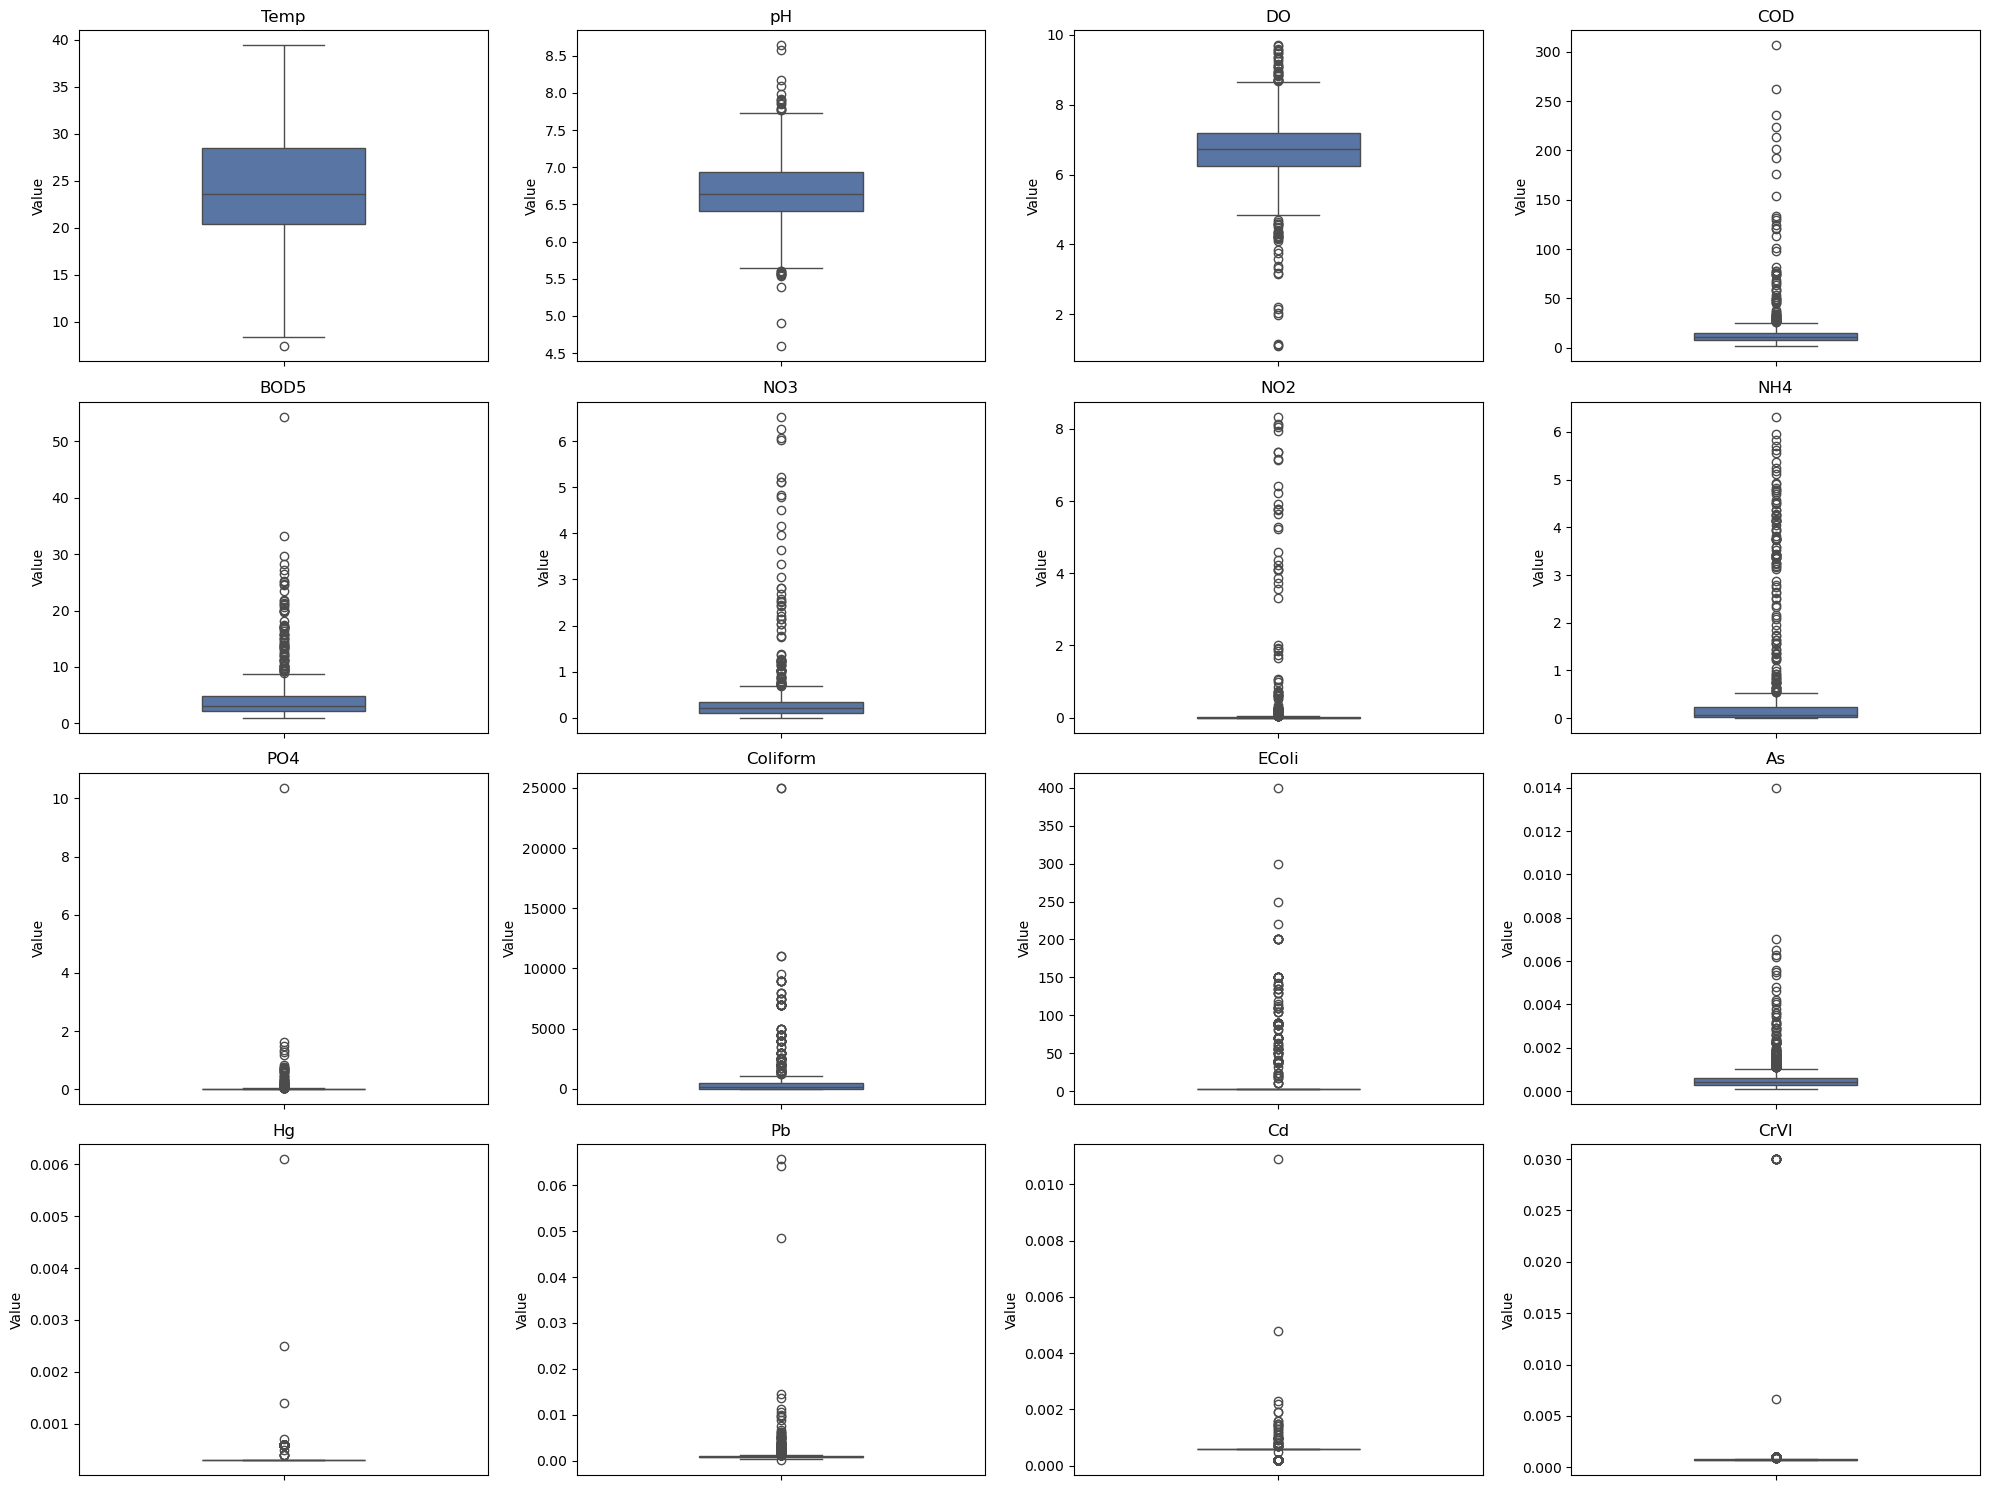

In [25]:
numeric_cols = df_analysis.select_dtypes(include='number').columns
n_numeric_cols = len(numeric_cols)

nrows = 4
ncols = 4

plt.figure(figsize=(20, 15)) # Adjusted figure size for a 3x5 grid

for i, col_name in enumerate(numeric_cols[:nrows * ncols]): # Iterate through the first 15 columns
    ax = plt.subplot(nrows, ncols, i + 1)
    sns.boxplot(
        y=df_analysis[col_name],
        ax=ax,
        color="#4c72b0",
        width=0.4
    )
    ax.set_title(col_name, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

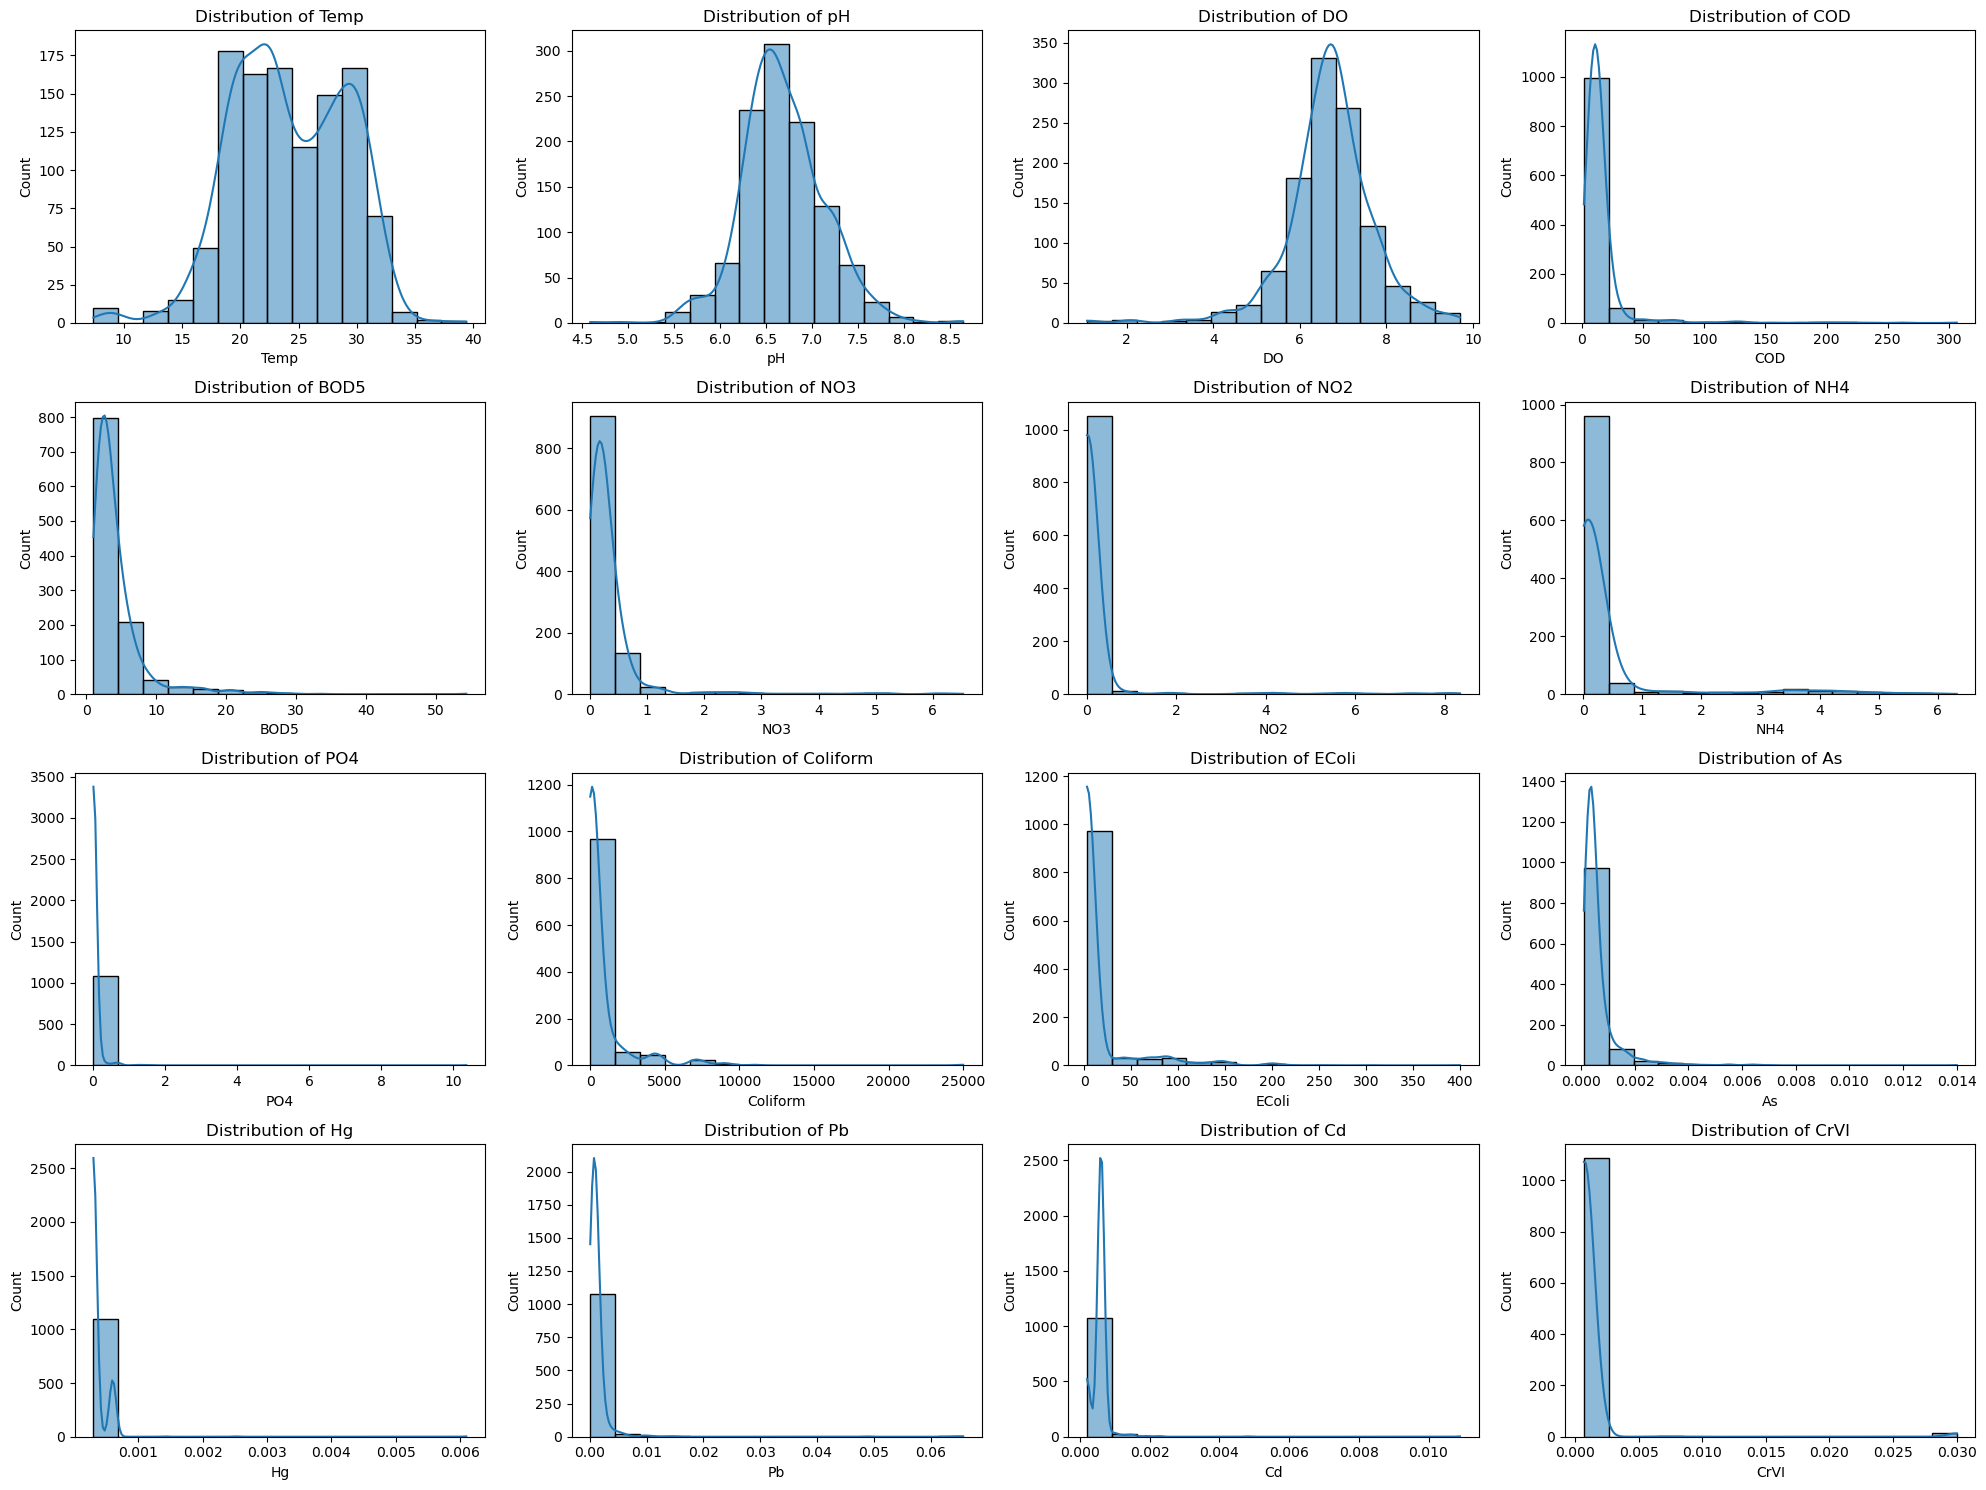

In [26]:
numeric_cols = df_analysis.select_dtypes(include='number').columns
n_numeric_cols = len(numeric_cols)

nrows = 4
ncols = 4

plt.figure(figsize=(20, 15)) # Adjusted figure size for a 3x5 grid

for i, col_name in enumerate(numeric_cols[:nrows * ncols]): # Iterate through the first 15 columns
    ax = plt.subplot(nrows, ncols, i + 1)
    sns.histplot(
        data=df_analysis,
        x=col_name,
        bins=15,
        kde=True,
        ax=ax
    )
    ax.set_title(f'Distribution of {col_name}', fontsize=12)
    ax.set_xlabel(col_name)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

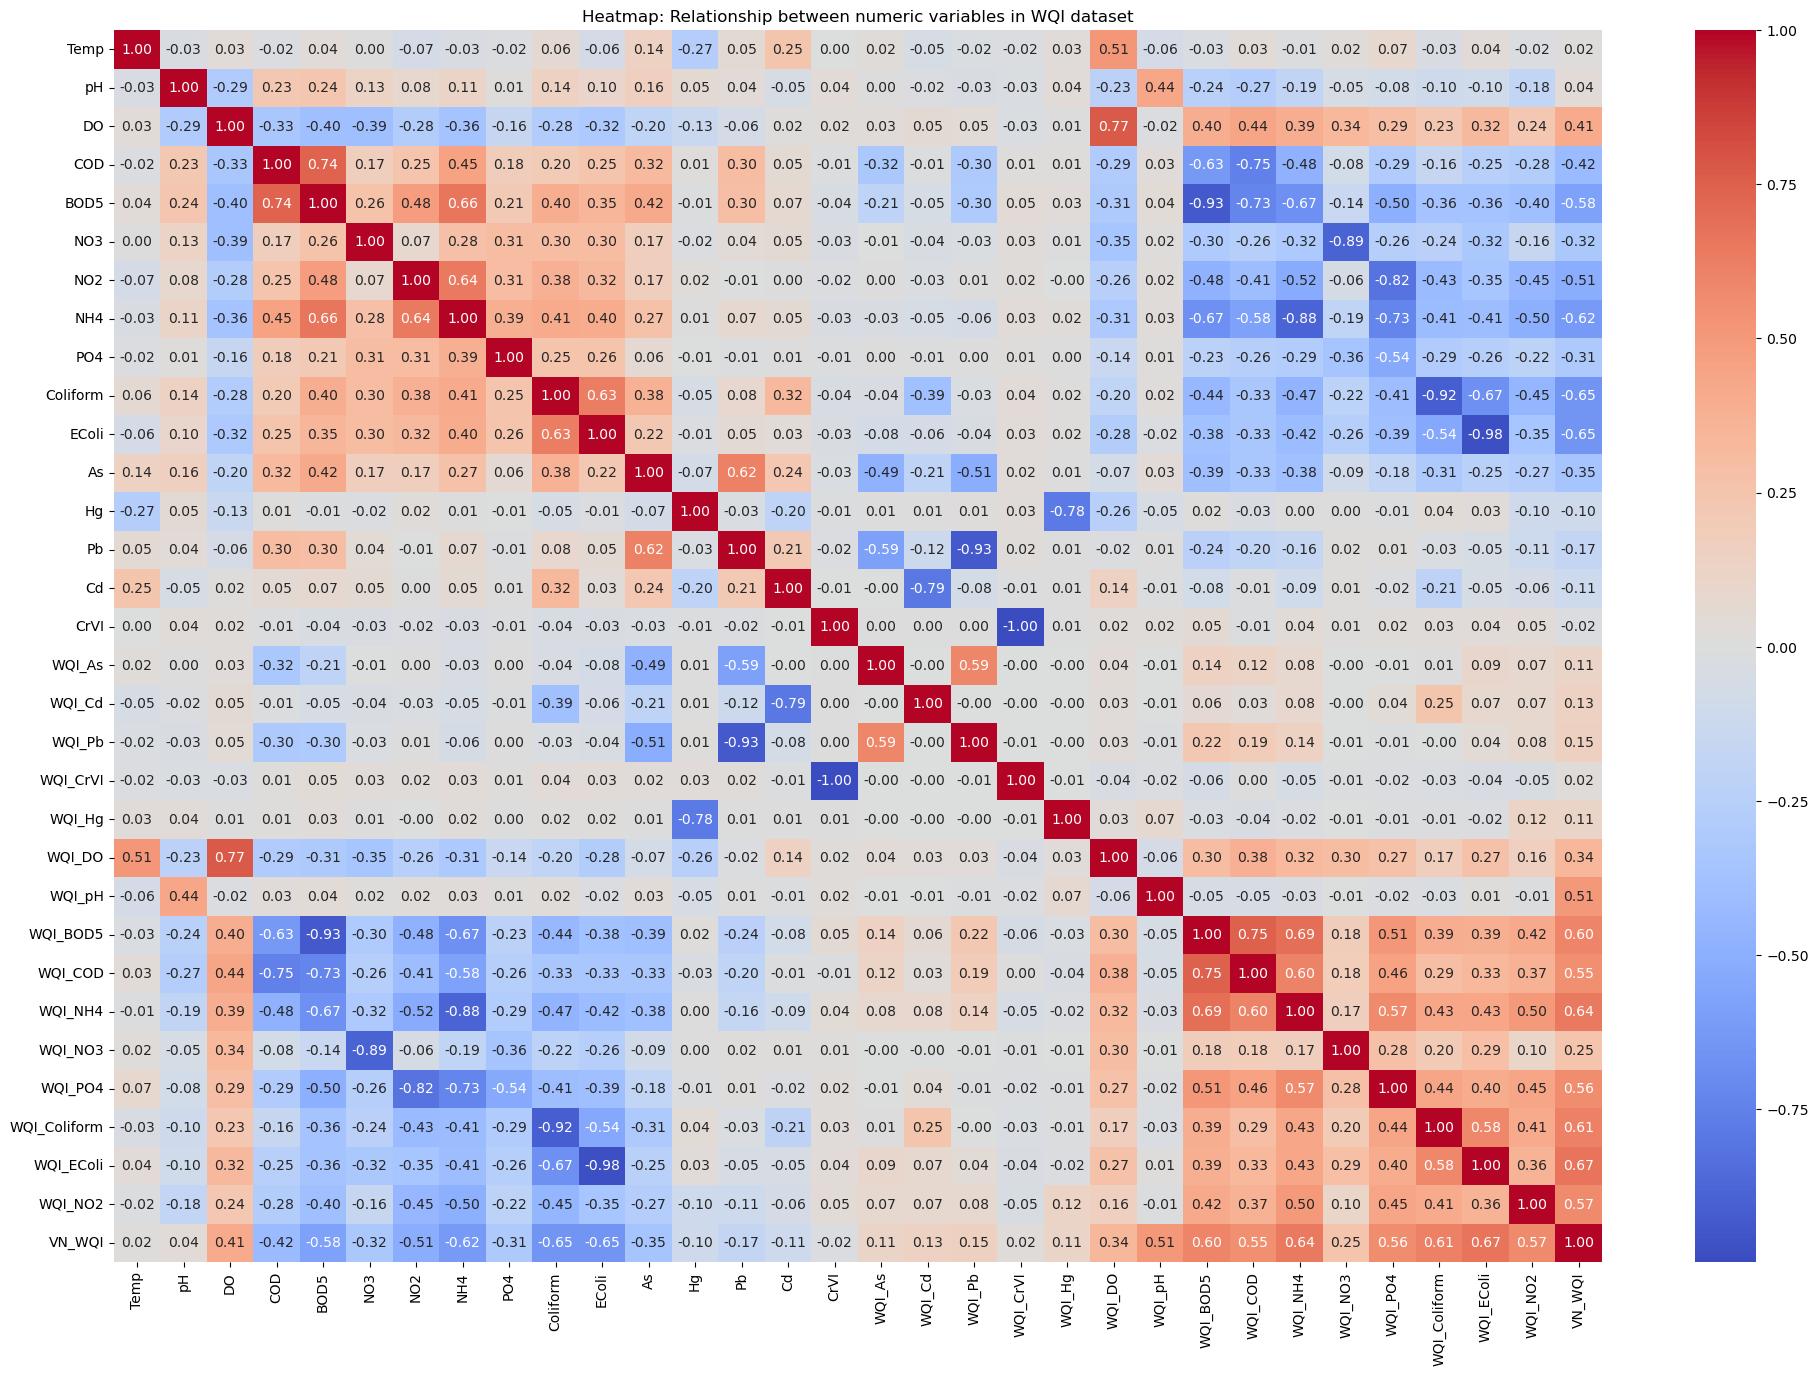

In [27]:
# Get numeric columns
numeric_cols = df_analysis.select_dtypes(include=['int64', 'float64']).columns
df_numeric = df_analysis[numeric_cols]

# Calculate correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(24, 16))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationship between numeric variables in WQI dataset")
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_16740\1925035792.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


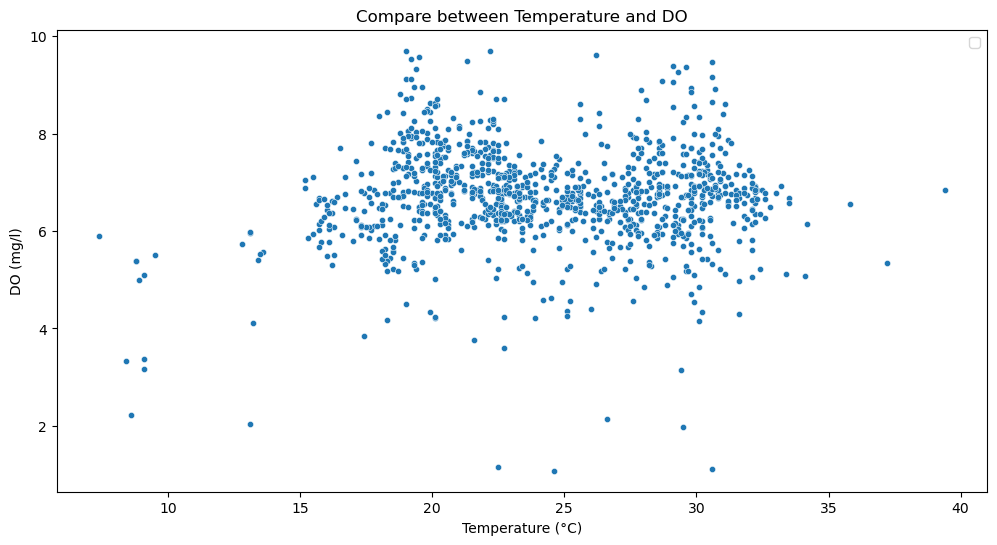

In [28]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_analysis, x='Temp', y='DO',s=20)
plt.title('Compare between Temperature and DO')
plt.xlabel('Temperature (°C)')
plt.ylabel('DO (mg/l)')
plt.legend()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_16740\647860588.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


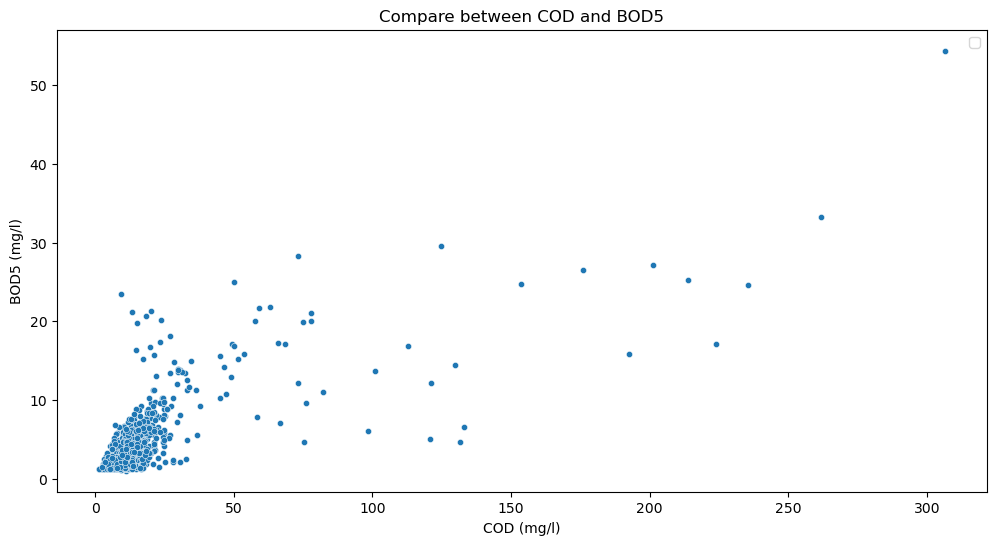

In [29]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_analysis, x='COD', y='BOD5',s=20)
plt.title('Compare between COD and BOD5')
plt.xlabel('COD (mg/l)')
plt.ylabel('BOD5 (mg/l)')
plt.legend()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_16740\1549559254.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


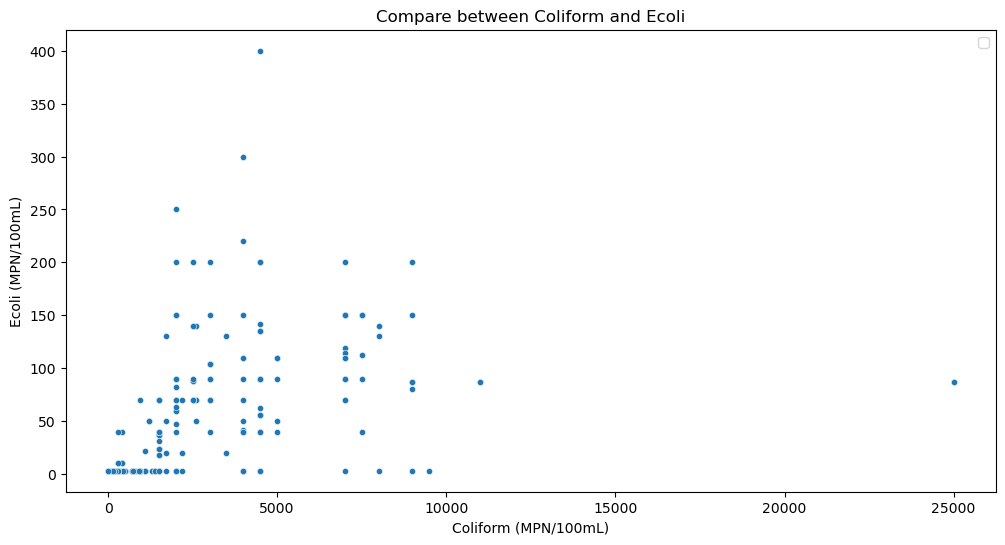

In [30]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_analysis, x='Coliform', y='EColi',s=20)
plt.title('Compare between Coliform and Ecoli')
plt.xlabel('Coliform (MPN/100mL)')
plt.ylabel('Ecoli (MPN/100mL)')
plt.legend()
plt.show()

# 3. Feature Engineering


---

In [31]:
def knn_pipeline_factory(**params):
        return Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsRegressor(**params)),
        ])

def lr_pipeline_factory(**params):
        return Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LinearRegression(**params)),
        ])

def svr_pipeline_factory(**params):
        return Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(**params)),
        ])

Standard scaling is applied for Linear Regression and K-Nearest Neighbors because these models are sensitive to the scale of features. On the other hand, Random Forest and Gradient Boosting do not require feature scaling, as they are tree-based models and are insensitive to the magnitude of the features.

# 4. Direct Measurement Inputs

## 4.1 Before applying feature selection

### 4.1.1. Classifier Training

#### Model Training

In [32]:
def prepare_wqi_features_target(df):
    """
    Shared preprocessing for modeling:
    1) KNN fill missing values
    2) Calculate WQI features/target
    3) Return X, y
    """
    df_filled = knn_fill_columns(df.copy())
    df_wqi = calculate_all_wqi(df_filled, metal_configs, params_config)

    X = df_wqi.drop(columns=["VN_WQI"])
    y = df_wqi["VN_WQI"]

    return X, y


def run_cv_with_wqi_preprocessing(
    df,
    algorithm,
    params,
    feature_cols,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS,
    model_fixed_params=None
):
    """
    Run KFold CV for one parameter set with project preprocessing.
    Returns mean RMSE, or detailed CV outputs when return_details=True.
    """
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    fixed = model_fixed_params or {}
    fold_mses = []
    oof_predictions = pd.Series(index=df.index, dtype=float)

    for train_idx, valid_idx in kf.split(df):
        train_raw = df.iloc[train_idx].copy()
        valid_raw = df.iloc[valid_idx].copy()

        X_train_cv, y_train_cv = prepare_wqi_features_target(train_raw)
        X_valid_cv, y_valid_cv = prepare_wqi_features_target(valid_raw)

        X_train_fold = X_train_cv[feature_cols]
        X_valid_fold = X_valid_cv[feature_cols]

        model = algorithm(**params, **fixed)

        model.fit(X_train_fold, y_train_cv)
        y_pred = model.predict(X_valid_fold)
        mse = mean_squared_error(y_valid_cv, y_pred)
        fold_mses.append(mse)

        # Store out-of-fold predictions on original row indices
        oof_predictions.loc[y_valid_cv.index] = y_pred

    mean_mse = float(np.mean(fold_mses))
        
    return mean_mse


def custom_grid_search_cv(
    df,
    param_grid,
    algorithm,
    feature_cols,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS,
    model_fixed_params=None
):
    """
    Generic custom GridSearchCV for this notebook pipeline.
    Returns: best_params, best_mse
    """
    param_names = list(param_grid.keys())
    param_values = [param_grid[name] for name in param_names]
    param_combinations = list(itertools.product(*param_values))

    best_mse = float("inf")
    best_params = None

    for combo in param_combinations:
        current_params = dict(zip(param_names, combo))
        mean_mse = run_cv_with_wqi_preprocessing(
            df=df,
            algorithm=algorithm,
            params=current_params,
            feature_cols=feature_cols,
            random_state=random_state,
            n_splits=n_splits,
            model_fixed_params=model_fixed_params,
        )

        if mean_mse < best_mse:
            best_mse = mean_mse
            best_params = current_params

    return best_params, best_mse

In [33]:
def tune_all_models_with_custom_cv(
    df,
    feature_cols,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS,
):
    """
    Run custom_grid_search_cv for RF, GB, KNN, LR, and SVR.
    Returns a dict with best_params and best_mse for each model.
    """

    rf_param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 20, 40],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.7, 1.0],
    }


    gb_param_grid = {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1, 0.2],
        "max_depth": [3, 5, 7],
    }

    knn_param_grid = {
        "n_neighbors": [3, 5, 7, 9],
        "weights": ["uniform", "distance"],
        "metric": ["minkowski", "euclidean", "manhattan"],
        "p": [1, 2],
    }

    lr_param_grid = {
        "fit_intercept": [True, False],
        "positive": [False, True],
    }

    svr_param_grid = {
        "C": [0.1, 1, 10, 100],
        "epsilon": [0.01, 0.1, 0.2],
        "gamma": ["scale", "auto", 0.01, 0.1],
    }

    model_specs = {
        "RandomForest": {
            "algorithm": RandomForestRegressor,
            "param_grid": rf_param_grid,
            "model_fixed_params": {"n_jobs": -1, "random_state": random_state},
        },
        "GradientBoosting": {
            "algorithm": GradientBoostingRegressor,
            "param_grid": gb_param_grid,
            "model_fixed_params": {"random_state": random_state},
        },
        "KNN": {
            "algorithm": knn_pipeline_factory,
            "param_grid": knn_param_grid,
            "model_fixed_params": None,
        },
        "LinearRegression": {
            "algorithm": lr_pipeline_factory,
            "param_grid": lr_param_grid,
            "model_fixed_params": None,
        },
        "SVR": {
            "algorithm": svr_pipeline_factory,
            "param_grid": svr_param_grid,
            "model_fixed_params": None,
        },
    }

    results = {}

    for model_name, spec in model_specs.items():
        best_params, best_mse = custom_grid_search_cv(
            df=df,
            param_grid=spec["param_grid"],
            algorithm=spec["algorithm"],
            feature_cols=feature_cols,
            random_state=random_state,
            n_splits=n_splits,
            model_fixed_params=spec["model_fixed_params"],
        )

        results[model_name] = {
            "best_params": best_params,
            "best_mse": best_mse,
        }

        print(f"[{model_name}] Best Params: {best_params}")
        print(f"[{model_name}] Best CV MSE: {best_mse}")
        print("-" * 60)

    return results

all_best_results = tune_all_models_with_custom_cv(
    df=final_data,
    feature_cols=[
            "Temp", "pH", "DO", "COD", "BOD5", "NO3", "NO2", "NH4", "PO4",
            "Coliform", "EColi", "As", "Hg", "Pb", "Cd", "CrVI"
        ],
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS
)

[RandomForest] Best Params: {'n_estimators': 50, 'max_depth': 40, 'min_samples_leaf': 2, 'max_features': 1.0}
[RandomForest] Best CV MSE: 11.214575258880378
------------------------------------------------------------
[GradientBoosting] Best Params: {'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 3}
[GradientBoosting] Best CV MSE: 7.435514241413626
------------------------------------------------------------
[KNN] Best Params: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 2}
[KNN] Best CV MSE: 30.16260317848527
------------------------------------------------------------
[LinearRegression] Best Params: {'fit_intercept': True, 'positive': False}
[LinearRegression] Best CV MSE: 51.05699380345627
------------------------------------------------------------
[SVR] Best Params: {'C': 100, 'epsilon': 0.2, 'gamma': 'scale'}
[SVR] Best CV MSE: 21.93554674954375
------------------------------------------------------------


In [34]:
def train_all_models(
    final_data,
    all_best_results,
    random_state=RANDOM_STATE,
    n_splits=5,
    feature_cols=None
):
    """
    Train models and return predictions ready for evaluate_models.

    Returns:
    - models: trained final models on full data
    - predictions: dict with short keys (RF, GB, LR, KNN, SVR)
    - predictions_dict: dict with display names for evaluate_models
    - y_eval: true target values aligned with prediction arrays
    - metrics_df: CV evaluation table with MSE/RMSE/MAE/R2
    """
    if feature_cols is None:
        feature_cols = [
            "Temp", "pH", "DO", "COD", "BOD5", "NO3", "NO2", "NH4", "PO4",
            "Coliform", "EColi", "As", "Hg", "Pb", "Cd", "CrVI"
        ]

    from sklearn.base import clone

    models = {}
    predictions = {}
    metrics_rows = []

    best_rf_params = all_best_results["RandomForest"]["best_params"]
    best_gb_params = all_best_results["GradientBoosting"]["best_params"]
    best_knn_params = all_best_results["KNN"]["best_params"]
    best_lr_params = all_best_results["LinearRegression"]["best_params"]
    best_svr_params = all_best_results["SVR"]["best_params"]

    model_specs = {
        "RF": {
            "build": lambda: RandomForestRegressor(
                **best_rf_params,
                n_jobs=-1,
                random_state=random_state
            ),
            "display": "Random Forest",
        },
        "GB": {
            "build": lambda: GradientBoostingRegressor(
                **best_gb_params,
                random_state=random_state
            ),
            "display": "Gradient Boosting",
        },
        "KNN": {
            "build": lambda: knn_pipeline_factory(**best_knn_params),
            "display": "K-Nearest Neighbors",
        },
        "LR": {
            "build": lambda: BaggingRegressor(
                estimator=lr_pipeline_factory(**best_lr_params),
                n_estimators=100,
                random_state=random_state,
            ),
            "display": "Linear Regression",
        },
        "SVR": {
            "build": lambda: BaggingRegressor(
                estimator=svr_pipeline_factory(**best_svr_params),
                n_estimators=100,
                random_state=random_state,
            ),
            "display": "Support Vector Regression",
        },
    }

    # Preprocess once, then run CV consistently for all models.
    X_full, y_full = prepare_wqi_features_target(final_data.copy())
    X_full = X_full[feature_cols]

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    y_eval = None

    for model_name, spec in model_specs.items():
        base_model = spec["build"]()
        oof_pred = pd.Series(index=y_full.index, dtype=float)

        for train_idx, valid_idx in kf.split(X_full):
            X_train_fold = X_full.iloc[train_idx]
            y_train_fold = y_full.iloc[train_idx]
            X_valid_fold = X_full.iloc[valid_idx]

            fold_model = clone(base_model)
            fold_model.fit(X_train_fold, y_train_fold)
            oof_pred.iloc[valid_idx] = fold_model.predict(X_valid_fold)

        valid_mask = oof_pred.notna() & y_full.notna()
        y_true_eval = y_full.loc[valid_mask]
        y_pred_eval = oof_pred.loc[valid_mask]

        predictions[model_name] = y_pred_eval.values

        mse = mean_squared_error(y_true_eval, y_pred_eval)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_true_eval, y_pred_eval)
        r2 = r2_score(y_true_eval, y_pred_eval)

        metrics_rows.append({
            "Model": spec["display"],
            "MSE": mse,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2,
        })

        # Train final model on full preprocessed data.
        base_model.fit(X_full, y_full)
        models[model_name] = base_model

        if y_eval is None:
            y_eval = y_true_eval

    predictions_dict = {
        "Random Forest": predictions.get("RF"),
        "Gradient Boosting": predictions.get("GB"),
        "Linear Regression": predictions.get("LR"),
        "K-Nearest Neighbors": predictions.get("KNN"),
        "Support Vector Regression": predictions.get("SVR"),
    }

    # Remove None values if a model was skipped.
    predictions_dict = {k: v for k, v in predictions_dict.items() if v is not None}

    metrics_df = pd.DataFrame(metrics_rows)
    metrics_df = metrics_df[["Model", "MSE", "RMSE", "MAE", "R2"]].round(4)

    return models, predictions, predictions_dict, y_eval, metrics_df


models, predictions, predictions_dict, y_eval, metrics_df = train_all_models(
    final_data=final_data,
    all_best_results=all_best_results,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS
)

rf_pred = predictions["RF"]
gb_pred = predictions["GB"]
lr_pred = predictions["LR"]
knn_pred = predictions["KNN"]
svr_pred = predictions["SVR"]

In [35]:
def evaluate_stacking(
    all_best_results,
    final_data,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS,
    feature_cols=None,
    meta_model=None,
):
    """
    Evaluate all stacking combinations with cross-validation on final_data.
    No train/test split is used.
    """
    if feature_cols is None:
        feature_cols = [
            "Temp", "pH", "DO", "COD", "BOD5", "NO3", "NO2", "NH4", "PO4",
            "Coliform", "EColi", "As", "Hg", "Pb", "Cd", "CrVI"
        ]

    best_rf_params = all_best_results["RandomForest"]["best_params"]
    best_gb_params = all_best_results["GradientBoosting"]["best_params"]
    best_knn_params = all_best_results["KNN"]["best_params"]
    best_lr_params = all_best_results["LinearRegression"]["best_params"]
    best_svr_params = all_best_results["SVR"]["best_params"]

    if meta_model is None:
        meta_model = LinearRegression()

    from sklearn.base import clone

    base_models = {
        "RF": RandomForestRegressor(**best_rf_params, n_jobs=-1, random_state=random_state),
        "KNN": knn_pipeline_factory(**best_knn_params),
        "LR": BaggingRegressor(
            estimator=lr_pipeline_factory(**best_lr_params),
            n_estimators=200,
            random_state=random_state,
        ),
        "SVR": BaggingRegressor(
            estimator=svr_pipeline_factory(**best_svr_params),
            n_estimators=200,
            random_state=random_state,
        ),
        "GB": GradientBoostingRegressor(**best_gb_params, random_state=random_state),
    }

    X_full, y_full = prepare_wqi_features_target(final_data.copy())
    X_full = X_full[feature_cols]

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    results = []
    model_names = list(base_models.keys())
    best_rmse = float("inf")
    best_combo = None

    for r in range(2, len(model_names) + 1):
        for combo in itertools.combinations(model_names, r):
            y_true_all = []
            y_pred_all = []

            for train_idx, valid_idx in kf.split(X_full):
                X_train_fold = X_full.iloc[train_idx]
                y_train_fold = y_full.iloc[train_idx]
                X_valid_fold = X_full.iloc[valid_idx]
                y_valid_fold = y_full.iloc[valid_idx]

                estimators = [(name.lower(), clone(base_models[name])) for name in combo]
                stacking = StackingRegressor(
                    estimators=estimators,
                    final_estimator=clone(meta_model),
                    n_jobs=-1,
                )

                stacking.fit(X_train_fold, y_train_fold)
                preds = stacking.predict(X_valid_fold)

                y_true_all.extend(y_valid_fold.tolist())
                y_pred_all.extend(preds.tolist())

            mse = mean_squared_error(y_true_all, y_pred_all)
            rmse = np.sqrt(mse)
            mae = mean_absolute_error(y_true_all, y_pred_all)
            r2 = r2_score(y_true_all, y_pred_all)

            results.append({
                "Base Models": " + ".join(combo),
                "Num Models": len(combo),
                "MSE": mse,
                "RMSE": rmse,
                "MAE": mae,
                "R2": r2,
            })

            if rmse < best_rmse:
                best_rmse = rmse
                best_combo = combo

    results_df = pd.DataFrame(results).sort_values(by="RMSE").reset_index(drop=True)

    # Refit the best stacking combination on the full preprocessed dataset.
    best_estimators = [(name.lower(), clone(base_models[name])) for name in best_combo]
    best_stacking_model = StackingRegressor(
        estimators=best_estimators,
        final_estimator=clone(meta_model),
        n_jobs=-1,
    )
    best_stacking_model.fit(X_full, y_full)

    return results_df, best_stacking_model

results_df, best_stacking_model = evaluate_stacking(
    all_best_results=all_best_results,
    final_data=final_data,
    random_state=RANDOM_STATE,
)

#### Model Evaluation

In [66]:
def evaluate_models(metrics_df, caption="Model Metrics"):
    df_show = metrics_df.copy()

    # Viết tắt tên model
    abbr_map = {
        "Random Forest": "RF",
        "Gradient Boosting": "GB",
        "Linear Regression": "LR",
        "K-Nearest Neighbors": "KNN",
        "Support Vector Regression": "SVR",
    }
    if "Model" in df_show.columns:
        df_show["Model"] = df_show["Model"].replace(abbr_map)

    # Đổi tên cột R2 -> R²
    if "R2" in df_show.columns:
        df_show = df_show.rename(columns={"R2": "R²"})

    fmt_map = {c: "{:.4f}" for c in ["MSE", "RMSE", "MAE", "R²"] if c in df_show.columns}

    metrics_table = (
        df_show.style
        .hide(axis="index")
        .format(fmt_map)
        .set_caption(caption)
        .set_table_attributes('style="width:100%; border-collapse:collapse; font-size:16px;"')
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#1e3a8a"),  # đổi từ #2563eb -> slate
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("border", "1px solid #d1d5db"),
                    ("padding", "10px 14px"),
                ],
            },
            # Header row -> blue
            {
                "selector": "th",
                "props": [
                    ("background-color", "#1e3a8a"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("border", "1px solid #d1d5db"),
                    ("padding", "10px 14px"),
                ],
            },
            # Data cells
            {
                "selector": "td",
                "props": [
                    ("text-align", "center"),
                    ("border", "1px solid #d1d5db"),
                    ("padding", "10px 14px"),
                    ("color", "#111827"),
                ],
            },
            # Zebra rows
            {
                "selector": "tbody tr:nth-child(odd) td",
                "props": [("background-color", "#ffffff")],
            },
            {
                "selector": "tbody tr:nth-child(even) td",
                "props": [("background-color", "#f3f4f6")],
            },
        ])
    )

    display(metrics_table)

# Gọi lại
evaluate_models(metrics_df)

Model,MSE,RMSE,MAE,R²
RF,11.0854,3.3295,1.3794,0.9357
GB,7.3064,2.7030,1.0385,0.9576
KNN,30.4605,5.5191,2.6207,0.8233
LR,50.4638,7.1038,4.0210,0.7072
SVR,25.3255,5.0324,2.4404,0.8531


In [69]:
def plot_results_table(
    results_df,
    title="Stacking Models Performance Metrics",
    figsize_width=16,
    row_height=0.35,
    font_size=14,
    header_color="#1e3a8a",   # dark blue
    top_row_color="#1e3a8a",  # dòng best model
    alt_row_color="#f3f4f6",
    top_n=5
):
    top_results = results_df.nsmallest(top_n, "RMSE").copy()

    # Keep arguments for backward compatibility
    _ = (figsize_width, row_height)

    format_map = {}
    for col in ["MSE", "RMSE", "MAE", "R2"]:
        if col in top_results.columns:
            format_map[col] = "{:.4f}"

    styled_table = (
        top_results.style
        .hide(axis="index")
        .format(format_map)
        .set_caption(f"{title} (Top {top_n})")
        .set_table_attributes('style="width:100%; border-collapse:collapse; font-size:16px;"')
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("font-size", "18px"),
                    ("font-weight", "bold"),
                    ("padding", "8px"),
                    ("color", "#111827"),
                ],
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", header_color),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("font-size", f"{font_size}px"),
                    ("border", "1px solid #d1d5db"),
                    ("padding", "10px 14px"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("text-align", "center"),
                    ("font-size", f"{font_size}px"),
                    ("color", "#111827"),
                    ("border", "1px solid #d1d5db"),
                    ("padding", "10px 14px"),
                ],
            },
            {
                "selector": "tbody tr:nth-child(odd) td",
                "props": [("background-color", "#ffffff")],
            },
            {
                "selector": "tbody tr:nth-child(even) td",
                "props": [("background-color", alt_row_color)],
            },
        ])
    )

    display(styled_table)

plot_results_table(results_df, top_n=5)

Base Models,Num Models,MSE,RMSE,MAE,R2
KNN + LR + SVR + GB,4,7.7991,2.7927,1.3957,0.9547
LR + GB,2,7.8157,2.7956,1.1663,0.9547
RF + KNN + LR + SVR + GB,5,7.8159,2.7957,1.3899,0.9547
RF + LR + GB,3,7.8315,2.7985,1.1665,0.9546
LR + SVR + GB,3,7.8941,2.8096,1.3860,0.9542


In [38]:
def plot_parallel_coordinates_all_models(
    results_df,
    metrics_df,
    title="All Models Performance Metrics",
    top_n=15
):
    df_plot = results_df.copy()

    # Normalize individual-model metrics to the same schema as stacking results
    individual_df = metrics_df.copy()
    rename_map = {'Model': 'Base Models'}
    individual_df = individual_df.rename(columns={k: v for k, v in rename_map.items() if k in individual_df.columns})
    if 'Num Models' not in individual_df.columns:
        individual_df['Num Models'] = 1

    required_cols = ['Base Models', 'Num Models', 'MSE', 'RMSE', 'MAE', 'R2']
    missing_cols = [c for c in required_cols if c not in individual_df.columns]
    if missing_cols:
        raise ValueError(f"metrics_df is missing required columns: {missing_cols}")

    df_plot = pd.concat([individual_df[required_cols], df_plot], ignore_index=True)
    df_plot = df_plot.nsmallest(top_n, 'RMSE').reset_index(drop=True)

    import plotly.express as px
    colors = px.colors.qualitative.Plotly
    n_models = len(df_plot)
    color_mapping = [colors[i % len(colors)] for i in range(n_models)]

    fig = go.Figure(data=
        go.Parcoords(
            line=dict(
                color=list(range(n_models)),
                colorscale=[[i / (n_models - 1), color_mapping[i]] for i in range(n_models)] if n_models > 1 else [[0, color_mapping[0]], [1, color_mapping[0]]],
                showscale=False
            ),
            dimensions=[
                dict(
                    range=[df_plot['MSE'].min() * 0.95, df_plot['MSE'].max() * 1.05],
                    label='MSE',
                    values=df_plot['MSE'].tolist(),
                    tickformat='.2f'
                ),
                dict(
                    range=[df_plot['RMSE'].min() * 0.95, df_plot['RMSE'].max() * 1.05],
                    label='RMSE',
                    values=df_plot['RMSE'].tolist(),
                    tickformat='.2f'
                ),
                dict(
                    range=[df_plot['MAE'].min() * 0.95, df_plot['MAE'].max() * 1.05],
                    label='MAE',
                    values=df_plot['MAE'].tolist(),
                    tickformat='.2f'
                ),
                dict(
                    range=[df_plot['R2'].min() - 0.01, 1.0],
                    label='R²',
                    values=df_plot['R2'].tolist(),
                    tickformat='.4f'
                )
            ],
            labelangle=-45,
            labelside='bottom'
        )
    )

    fig.update_layout(
        title=dict(
            text=f"{title}<br><sub>Top {top_n} Models by RMSE</sub>",
            font=dict(size=16, family='Arial, sans-serif', color='#2c3e50'),
            x=0.5,
            xanchor='center'
        ),
        plot_bgcolor='white',
        paper_bgcolor='white',
        font=dict(size=11, family='Arial, sans-serif'),
        height=800,
        width=1400,
        margin=dict(l=250, r=350, t=120, b=100),
        hovermode='closest',
        showlegend=True,
        legend=dict(
            orientation="v",
            yanchor="top",
            y=1.0,
            xanchor="left",
            x=1.02,
            bgcolor="rgba(255, 255, 255, 0.95)",
            bordercolor="gray",
            borderwidth=1,
            font=dict(size=9)
        ),
        xaxis=dict(showgrid=False),
        yaxis=dict(showgrid=False)
    )

    for i, row in df_plot.iterrows():
        fig.add_trace(go.Scatter(
            x=[None], y=[None],
            mode='markers',
            marker=dict(size=10, color=color_mapping[i]),
            legendgroup=row['Base Models'],
            showlegend=True,
            name=f"{i+1}. {row['Base Models'][:30]}",
            hovertemplate=f"<b>{row['Base Models']}</b><br>" +
                         f"Num Models: {int(row['Num Models'])}<br>" +
                         f"MSE: {row['MSE']:.4f}<br>" +
                         f"RMSE: {row['RMSE']:.4f}<br>" +
                         f"MAE: {row['MAE']:.4f}<br>" +
                         f"R²: {row['R2']:.4f}<br>" +
                         "<extra></extra>"
        ))

    return fig

fig_all_models_41 = plot_parallel_coordinates_all_models(
    results_df=results_df,
    metrics_df=metrics_df,
    title="4.1: All Models Performance Metrics - Individual vs Stacking Ensemble (Before Feature Selection)",
    top_n=15
)

fig_all_models_41.show()

### 4.1.2. Feature Importance

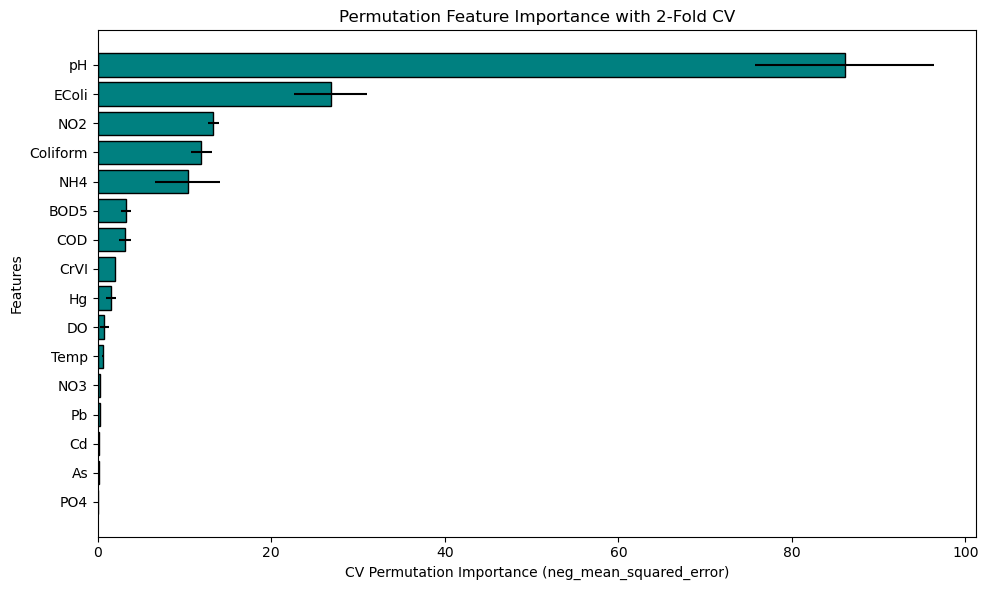

Mean estimator score across folds: 0.9550


,Feature,Importance_Mean,Importance_STD
0,pH,86.074918,10.297393
1,EColi,26.822946,4.180607
2,NO2,13.304782,0.634148
3,Coliform,11.943921,1.225868
4,NH4,10.352949,3.736272
5,BOD5,3.210645,0.577400
6,COD,3.149968,0.651720
7,CrVI,1.953138,0.022516
8,Hg,1.509323,0.607656
9,DO,0.748940,0.526100


In [39]:
from sklearn.base import clone
from sklearn.model_selection import KFold

def plot_permutation_importance(
    df,
    estimator,
    feature_cols,
    n_splits=N_SPLITS,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring="neg_mean_squared_error",
    figsize=(10, 6),
    color="teal",
):
    """
    Compute permutation importance with KFold CV.

    strict_no_leakage=True:
      - split raw df per fold
      - fit KNN imputer on train fold only, transform valid fold
      - calculate WQI features/target after split
    strict_no_leakage=False:
      - use prepare_wqi_features_target separately on train and valid folds
    """
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    fold_importances = []
    fold_scores = []

    for train_idx, valid_idx in kf.split(df):
        train_raw = df.iloc[train_idx].copy()
        valid_raw = df.iloc[valid_idx].copy()

        X_train_cv, y_train_cv = prepare_wqi_features_target(train_raw)
        X_valid_cv, y_valid_cv = prepare_wqi_features_target(valid_raw)

        X_train_fold = X_train_cv[feature_cols]
        X_valid_fold = X_valid_cv[feature_cols]

        model_fold = clone(estimator)
        model_fold.fit(X_train_fold, y_train_cv)
        fold_scores.append(model_fold.score(X_valid_fold, y_valid_cv))

        p = permutation_importance(
            model_fold,
            X_valid_fold,
            y_valid_cv,
            n_repeats=n_repeats,
            random_state=random_state,
            scoring=scoring,
        )
        fold_importances.append(p.importances_mean)

    importances = np.vstack(fold_importances)
    mean_importance = importances.mean(axis=0)
    std_importance = importances.std(axis=0)

    importance_df = pd.DataFrame({
        'Feature': feature_cols,
        'Importance_Mean': mean_importance,
        'Importance_STD': std_importance,
    }).sort_values('Importance_Mean', ascending=False).reset_index(drop=True)

    # Plot top to bottom with largest importance on top
    plot_df = importance_df.iloc[::-1]
    plt.figure(figsize=figsize)
    plt.barh(
        plot_df['Feature'],
        plot_df['Importance_Mean'],
        xerr=plot_df['Importance_STD'],
        color=color,
        edgecolor='black',
    )
    plt.xlabel(f"CV Permutation Importance ({scoring})")
    plt.ylabel('Features')
    plt.title(f"Permutation Feature Importance with {n_splits}-Fold CV")
    plt.tight_layout()
    plt.show()

    print(f"Mean estimator score across folds: {np.mean(fold_scores):.4f}")
    return importance_df


# Example: CV permutation importance on stacking model (raw data -> split -> preprocess)
perm_importance_cv_df = plot_permutation_importance(
    df=final_data.copy(),
    estimator=best_stacking_model,
    feature_cols=[
        "Temp", "pH", "DO", "COD", "BOD5", "NO3", "NO2", "NH4", "PO4",
        "Coliform", "EColi", "As", "Hg", "Pb", "Cd", "CrVI"
    ],
    n_splits=N_SPLITS,
    n_repeats=15,
    scoring="neg_mean_squared_error",
)

perm_importance_cv_df

## 4.2. After applying feature selection

### 4.2.1. Classifier Training

#### Model Training

In [40]:
all_best_results_retrain = tune_all_models_with_custom_cv(
    df=final_data,
    feature_cols=[
        "pH", "EColi", "NO2", "Coliform", "NH4", "COD",
        "CrVI", "Hg", "DO", "Temp"
    ],
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS
)

[RandomForest] Best Params: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0}
[RandomForest] Best CV MSE: 11.039079467084642
------------------------------------------------------------
[GradientBoosting] Best Params: {'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 3}
[GradientBoosting] Best CV MSE: 7.865617042402517
------------------------------------------------------------
[KNN] Best Params: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 2}
[KNN] Best CV MSE: 27.296876961021063
------------------------------------------------------------
[LinearRegression] Best Params: {'fit_intercept': True, 'positive': False}
[LinearRegression] Best CV MSE: 50.82335105890963
------------------------------------------------------------
[SVR] Best Params: {'C': 100, 'epsilon': 0.01, 'gamma': 'auto'}
[SVR] Best CV MSE: 16.538439105218963
------------------------------------------------------------


In [41]:
models_retrain, predictions_retrain, predictions_dict_retrain, y_eval_retrain, metrics_df_retrain = train_all_models(
    final_data=final_data,
    all_best_results=all_best_results_retrain,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS,
    feature_cols=[
        "pH", "EColi", "NO2", "Coliform", "NH4", "COD",
        "CrVI", "Hg", "DO", "Temp"
    ]
)

rf_pred_retrain = predictions_retrain["RF"]
gb_pred_retrain = predictions_retrain["GB"]
lr_pred_retrain = predictions_retrain["LR"]
knn_pred_retrain = predictions_retrain["KNN"]
svr_pred_retrain = predictions_retrain["SVR"]

In [42]:
results_df_retrain, best_stacking_model_retrain = evaluate_stacking(
    all_best_results=all_best_results_retrain,
    final_data=final_data,
    random_state=RANDOM_STATE,
    feature_cols=[
        "pH", "EColi", "NO2", "Coliform", "NH4", "COD",
        "CrVI", "Hg", "DO", "Temp"
    ]
)

### Model Evaluation

In [70]:
evaluate_models(metrics_df_retrain)

Model,MSE,RMSE,MAE,R²
RF,10.6258,3.2597,1.3506,0.9383
GB,7.4944,2.7376,1.1744,0.9565
KNN,27.4005,5.2345,2.5301,0.8410
LR,50.8650,7.1320,4.0810,0.7049
SVR,17.9323,4.2347,2.0889,0.8960


In [71]:
plot_results_table(results_df_retrain, top_n=5)

Base Models,Num Models,MSE,RMSE,MAE,R2
LR + GB,2,7.9135,2.8131,1.2684,0.9541
RF + LR + GB,3,8.1408,2.8532,1.2871,0.9528
KNN + LR + GB,3,8.1733,2.8589,1.3012,0.9526
KNN + LR + SVR + GB,4,8.1776,2.8596,1.4872,0.9526
LR + SVR + GB,3,8.1856,2.8610,1.4868,0.9525


In [45]:
fig_all_models_retrain = plot_parallel_coordinates_all_models(
    results_df=results_df_retrain,
    metrics_df=metrics_df_retrain,
    title="4.2: All Models Performance Metrics - Individual vs Stacking Ensemble (After Feature Selection)",
    top_n=15
 )

fig_all_models_retrain.show()

# 5. Feature Engineered Inputs (WQI_SI)


## 5.1 Before applying feature selection


### 5.1.1. Classifier Training


#### Model Training

In [46]:
all_best_results_WQIInput = tune_all_models_with_custom_cv(
    df=final_data,
    feature_cols=['WQI_pH', 'WQI_DO', 'WQI_COD', 'WQI_BOD5',
                'WQI_NO3', 'WQI_NO2', 'WQI_NH4', 'WQI_PO4',
                'WQI_Coliform', 'WQI_EColi', 'WQI_As', 'WQI_Hg', 'WQI_Pb',
                'WQI_Cd', 'WQI_CrVI'],
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS
) 

[RandomForest] Best Params: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0}
[RandomForest] Best CV MSE: 8.390423165154266
------------------------------------------------------------
[GradientBoosting] Best Params: {'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 3}
[GradientBoosting] Best CV MSE: 6.067025737226507
------------------------------------------------------------
[KNN] Best Params: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 2}
[KNN] Best CV MSE: 7.129682472760571
------------------------------------------------------------
[LinearRegression] Best Params: {'fit_intercept': True, 'positive': True}
[LinearRegression] Best CV MSE: 1.0472472616025381
------------------------------------------------------------
[SVR] Best Params: {'C': 100, 'epsilon': 0.2, 'gamma': 0.01}
[SVR] Best CV MSE: 2.0795036708502694
------------------------------------------------------------


In [47]:
models_WQIInput, predictions_WQIInput, predictions_dict_WQIInput, y_eval_WQIInput, metrics_df_WQIInput = train_all_models(
    final_data=final_data,
    all_best_results=all_best_results_WQIInput,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS,
    feature_cols=['WQI_pH', 'WQI_DO', 'WQI_COD', 'WQI_BOD5',
                'WQI_NO3', 'WQI_NO2', 'WQI_NH4', 'WQI_PO4',
                'WQI_Coliform', 'WQI_EColi', 'WQI_As', 'WQI_Hg', 'WQI_Pb',
                'WQI_Cd', 'WQI_CrVI']
)

rf_pred_WQIInput = predictions_WQIInput["RF"]
gb_pred_WQIInput = predictions_WQIInput["GB"]
lr_pred_WQIInput = predictions_WQIInput["LR"]
knn_pred_WQIInput = predictions_WQIInput["KNN"]
svr_pred_WQIInput = predictions_WQIInput["SVR"]

In [48]:
results_df_WQIInput, best_stacking_model_WQIInput = evaluate_stacking(
    all_best_results=all_best_results_WQIInput,
    final_data=final_data,
    random_state=RANDOM_STATE,
    feature_cols=['WQI_pH', 'WQI_DO', 'WQI_COD', 'WQI_BOD5',
                'WQI_NO3', 'WQI_NO2', 'WQI_NH4', 'WQI_PO4',
                'WQI_Coliform', 'WQI_EColi', 'WQI_As', 'WQI_Hg', 'WQI_Pb',
                'WQI_Cd', 'WQI_CrVI']
)

#### Model Evaluation

In [72]:
evaluate_models(metrics_df_WQIInput)

Model,MSE,RMSE,MAE,R²
RF,8.4258,2.9027,1.0172,0.9511
GB,7.0241,2.6503,0.9134,0.9592
KNN,7.2542,2.6934,0.9481,0.9579
LR,1.5893,1.2607,0.4732,0.9908
SVR,2.9247,1.7102,0.5025,0.9830


In [73]:
plot_results_table(results_df_WQIInput, top_n=5)

Base Models,Num Models,MSE,RMSE,MAE,R2
RF + KNN + LR + SVR,4,1.2286,1.1084,0.4751,0.9929
RF + LR + SVR,3,1.2291,1.1087,0.4769,0.9929
KNN + LR + SVR,3,1.2293,1.1087,0.4753,0.9929
LR + SVR,2,1.2337,1.1107,0.4790,0.9928
KNN + LR + SVR + GB,4,1.2401,1.1136,0.4754,0.9928


In [51]:
fig_all_models_51 = plot_parallel_coordinates_all_models(
    results_df=results_df_WQIInput,
    metrics_df=metrics_df_WQIInput,
    title="5.1: All Models Performance Metrics - Individual vs Stacking Ensemble (WQI Input - Before Feature Selection)",
    top_n=15
 )

fig_all_models_51.show()

### 5.1.2. Feature Importance

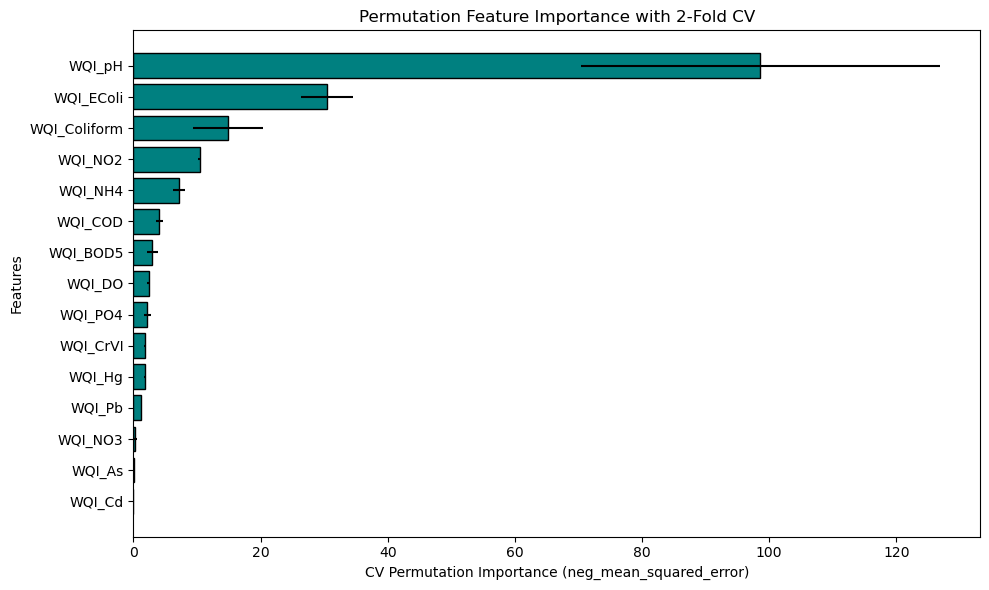

Mean estimator score across folds: 0.9930


In [52]:
perm_importance_cv_df_51 = plot_permutation_importance(
    df=final_data.copy(),
    estimator=best_stacking_model_WQIInput,
    feature_cols=['WQI_pH', 'WQI_DO', 'WQI_COD', 'WQI_BOD5',
                'WQI_NO3', 'WQI_NO2', 'WQI_NH4', 'WQI_PO4',
                'WQI_Coliform', 'WQI_EColi', 'WQI_As', 'WQI_Hg', 'WQI_Pb',
                'WQI_Cd', 'WQI_CrVI'],
    n_splits=N_SPLITS,
    n_repeats=15,
    scoring="neg_mean_squared_error",
)

## 5.2. After applying feature selection

### 5.2.1. Classifier Training

#### Data Splitting

In [53]:
all_best_results_WQIInput_retrain = tune_all_models_with_custom_cv(
    df=final_data,
    feature_cols=['WQI_pH', "WQI_EColi", "WQI_Coliform", "WQI_NO2",
                  "WQI_NH4", "WQI_COD", "WQI_DO", "WQI_PO4",
                    "WQI_CrVI", "WQI_Hg", "WQI_Pb"],
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS
)

[RandomForest] Best Params: {'n_estimators': 50, 'max_depth': 40, 'min_samples_leaf': 1, 'max_features': 1.0}
[RandomForest] Best CV MSE: 8.823757047974798
------------------------------------------------------------
[GradientBoosting] Best Params: {'n_estimators': 200, 'learning_rate': 0.2, 'max_depth': 3}
[GradientBoosting] Best CV MSE: 7.308259250367483
------------------------------------------------------------
[KNN] Best Params: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'minkowski', 'p': 2}
[KNN] Best CV MSE: 6.3497078154278785
------------------------------------------------------------
[LinearRegression] Best Params: {'fit_intercept': True, 'positive': False}
[LinearRegression] Best CV MSE: 1.5968103105244462
------------------------------------------------------------
[SVR] Best Params: {'C': 100, 'epsilon': 0.2, 'gamma': 0.01}
[SVR] Best CV MSE: 2.2936964011560272
------------------------------------------------------------


#### Model Training

In [54]:
models_WQIInput_retrain, predictions_WQIInput_retrain, predictions_dict_WQIInput_retrain, y_eval_WQIInput_retrain, metrics_df_WQIInput_retrain = train_all_models(
    final_data=final_data,
    all_best_results=all_best_results_WQIInput_retrain,
    random_state=RANDOM_STATE,
    n_splits=N_SPLITS,
    feature_cols=['WQI_pH', "WQI_EColi", "WQI_Coliform", "WQI_NO2",
                  "WQI_NH4", "WQI_COD", "WQI_DO", "WQI_PO4",
                    "WQI_CrVI", "WQI_Hg", "WQI_Pb"],
)

rf_pred_WQIInput_retrain = predictions_WQIInput_retrain["RF"]
gb_pred_WQIInput_retrain = predictions_WQIInput_retrain["GB"]
lr_pred_WQIInput_retrain = predictions_WQIInput_retrain["LR"]
knn_pred_WQIInput_retrain = predictions_WQIInput_retrain["KNN"]
svr_pred_WQIInput_retrain = predictions_WQIInput_retrain["SVR"]

In [55]:
results_df_WQIInput_retrain, best_stacking_model_WQIInput_retrain = evaluate_stacking(
    all_best_results=all_best_results_WQIInput_retrain,
    final_data=final_data,
    random_state=RANDOM_STATE,
    feature_cols=['WQI_pH', "WQI_EColi", "WQI_Coliform", "WQI_NO2",
                  "WQI_NH4", "WQI_COD", "WQI_DO", "WQI_PO4",
                    "WQI_CrVI", "WQI_Hg", "WQI_Pb"],
)

#### Model Evaluation

In [74]:
evaluate_models(metrics_df_WQIInput)

Model,MSE,RMSE,MAE,R²
RF,8.4258,2.9027,1.0172,0.9511
GB,7.0241,2.6503,0.9134,0.9592
KNN,7.2542,2.6934,0.9481,0.9579
LR,1.5893,1.2607,0.4732,0.9908
SVR,2.9247,1.7102,0.5025,0.9830


In [75]:
plot_results_table(results_df_WQIInput_retrain, top_n=5)

Base Models,Num Models,MSE,RMSE,MAE,R2
RF + KNN + LR + SVR,4,1.4271,1.1946,0.6932,0.9917
KNN + LR + SVR,3,1.4352,1.1980,0.6963,0.9917
KNN + LR + SVR + GB,4,1.4355,1.1981,0.6925,0.9917
RF + LR + SVR,3,1.4395,1.1998,0.6994,0.9916
RF + KNN + LR + SVR + GB,5,1.4598,1.2082,0.6968,0.9915


In [58]:
fig_all_models_52 = plot_parallel_coordinates_all_models(
    results_df=results_df_WQIInput_retrain,
    metrics_df=metrics_df_WQIInput_retrain,
    title="5.2: All Models Performance Metrics - Individual vs Stacking Ensemble (WQI Input - After Feature Selection)"
 )

fig_all_models_52.show()

# 6. Traditional WQI Formula Evaluation

In [59]:
wqi_data_droped_v3 = df_analysis.copy()
wqi_data_droped_v3.drop({'Coliform', 'BOD5', 'NO3', 'Cd', 'As', 'VN_WQI'}, axis=1, inplace=True)
wqi_data_droped_v3 = calculate_all_wqi(wqi_data_droped_v3)

TypeError: calculate_all_wqi() missing 2 required positional arguments: 'metal_configs' and 'params_config'

In [ ]:
y1 = wqi_data_droped_v3['VN_WQI']
y2 = df_analysis['VN_WQI']
print("Retrained Data - MSE:", mean_squared_error(y2, y1))
print("Retrained Data - RMSE:", np.sqrt(mean_squared_error(y2, y1)))
print("Retrained Data - MAE:", mean_absolute_error(y2, y1))
print("Retrained Data - R^2:", r2_score(y2, y1))

Retrained Data - MSE: 0.0
Retrained Data - RMSE: 0.0
Retrained Data - MAE: 0.0
Retrained Data - R^2: 1.0


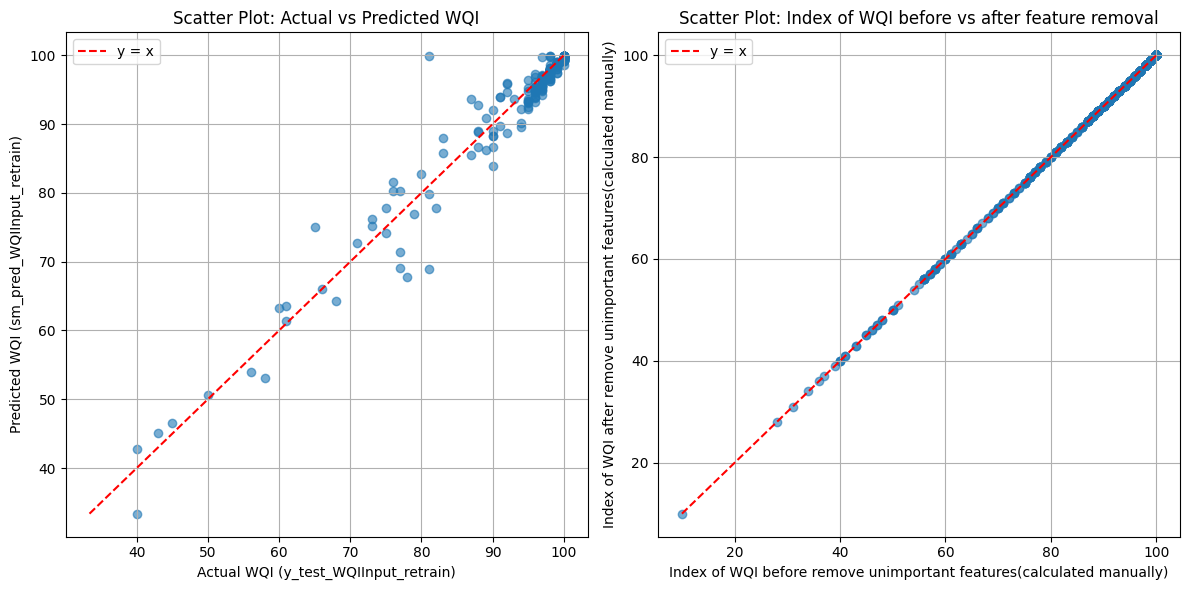

In [ ]:
# Side-by-side scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot 1: Actual vs Predicted WQI
axes[0].scatter(y_test_WQIInput_retrain.values, sm_pred_WQIInput_retrain, alpha=0.6)
min_v1 = min(y_test_WQIInput_retrain.min(), sm_pred_WQIInput_retrain.min())
max_v1 = max(y_test_WQIInput_retrain.max(), sm_pred_WQIInput_retrain.max())
axes[0].plot([min_v1, max_v1], [min_v1, max_v1], 'r--', label='y = x')
axes[0].set_xlabel('Actual WQI (y_test_WQIInput_retrain)')
axes[0].set_ylabel('Predicted WQI (sm_pred_WQIInput_retrain)')
axes[0].set_title('Scatter Plot: Actual vs Predicted WQI')
axes[0].legend()
axes[0].grid(True)

# Plot 2: Manual vs Reduced-feature WQI
manual_index = df_analysis['VN_WQI']
ml_index = wqi_data_droped_v3['VN_WQI']
axes[1].scatter(manual_index, ml_index, alpha=0.6)
min_v2 = min(manual_index.min(), ml_index.min())
max_v2 = max(manual_index.max(), ml_index.max())
axes[1].plot([min_v2, max_v2], [min_v2, max_v2], 'r--', label='y = x')
axes[1].set_xlabel('Index of WQI before remove unimportant features(calculated manually)')
axes[1].set_ylabel('Index of WQI after remove unimportant features(calculated manually)')
axes[1].set_title('Scatter Plot: Index of WQI before vs after feature removal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()